# 05. Модель: прогноз инцидентов на сутки вперед

**Что делаем.** Каждые сутки в 00:00 сервис должен сказать диспетчеру по каждому объекту коллектора, насколько
вероятен в ближайшие 24 часа отказ оборудования, пожар, подтопление или любой инцидент, и где на объекте искать.
ТЗ требует вероятность, горизонт не меньше 24 часов, локацию и тип инцидента, а целевые Precision и Recall
оставляет выбрать команде. Здесь мы обучаем модели градиентного бустинга (LightGBM) на готовой матрице признаков
«объект × сутки», честно сравниваем их с простым частотным правилом и со случайным выбором, калибруем вероятности,
выбираем уровни риска с ограничением нагрузки на диспетчера, объясняем отдельные прогнозы, ранжируем каналы и
пикеты объекта и сохраняем все, что нужно сервису.

**Главное правило оценки – будущее не подсматриваем.** Параметры подбираем только внутри 2019-2024 годов,
калибровку и пороги проверяем по схеме «подобрали на одном году – проверили на следующем», а к первому полугодию
2026 года (тест) модели применяем один раз, когда все решения уже записаны. Честно оговоримся: этот период уже
просматривался предыдущими версиями цепочки, поэтому защита от подгонки под тест здесь в том, что ни одно решение
не принимается по нему (раздел 2). Каждая цифра качества стоит рядом с частотным прогнозом, постоянной вероятностью
или случайным выбором.

**Как устроен ноутбук.**

0. Задача и данные
1. Как будем мерить
2. Схема проверки
3. Первая модель на скользящих фолдах и шум сида
4. Подбор параметров
5. Финальная модель и валидация 2025
6. На что опирается модель: вклады, абляции, риск «предсказываем работы»
7. Калибровка
8. Уровни риска с потолком нагрузки
9. Газ, потеря связи и неисправность охраны: сглаженная частота
10. Объяснения прогноза и где искать на объекте
11. Тест 2026: один проход и артефакты для сервиса
12. Итоги для заказчика

Все времена московские. «Инцидент» здесь – тревожный эпизод журнала СМВУ длительностью от минуты (потеря связи –
от 10 минут), а не подтвержденное диспетчером происшествие: журнала ОДС в данных нет.

In [1]:
import glob
import json
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display
from sklearn.metrics import roc_auc_score

from annanas import aggregates as agg
from annanas import episodes as ep
from annanas import location as loc
from annanas import maintenance as mnt
from annanas import modeling as md
from annanas.paths import PROCESSED_DIR, PROJECT_ROOT

MODELS_DIR = PROCESSED_DIR / "models"
PPR_WINDOWS_FILE = PROCESSED_DIR / "maintenance" / "ppr_windows.parquet"
FEATURES_CONTEXT_FILE = PROCESSED_DIR / "features_context.json"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
KEY = ["ид_объект", "день"]

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}".replace(",", " "))

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
GREY, INK, INK2 = "#9a9994", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (12, 4.5), "figure.dpi": 110, "figure.constrained_layout.use": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "legend.frameon": False, "lines.linewidth": 1.5, "axes.prop_cycle": plt.cycler(color=PALETTE),
})
ROLE_COLOR = {"модель": PALETTE[0], "частотный": PALETTE[1], "константа": GREY}


def n(v) -> str:
    """Число с пробелом-разделителем тысяч."""
    return f"{v:,.0f}".replace(",", " ")

## 0. Задача и данные

Вход – матрица «объект × сутки». В строке суток `D` лежат признаки, посчитанные только по событиям, известным до
`D 00:00`, и цели: `цель_<класс>` = 1, если в окне `[D 00:00, D + 24 ч)` на объекте начался эпизод класса. Столбец
`маска` помечает сутки, которые нельзя ни учить, ни оценивать: переход на новую СМВУ, сбои сбора данных, сутки до
подключения объекта (до его первой записи в журнале) и сутки, когда постоянно пишущий объект накануне молчал весь
день (это похоже на обрыв связи, а не на спокойствие), а также сутки плановых работ аппаратуры контроля метана
(ППР АКМ) с запасом ±3 суток. Во время ППР датчики метана снимают, возят на поверку, возвращают и проверяют
тестовым газом, поэтому журнал в эти дни полон «Обнаружен газ» и отказов, которые никакой угрозой не являются.
Окна ППР взяты из графика заказчика на 2026 год, а для прошлых лет найдены по журналу: такие проверки видны как
«Обнаружен газ» сразу на большинстве газовых каналов объекта в рабочее время, ежегодно в одном и том же месяце.
Тихие сутки подключенного объекта, когда тревог просто не
было, – обычные отрицательные примеры: именно такие сутки сервис будет видеть каждый день, и модель должна уметь
говорить в них «риск низкий». `выборка` делит время на обучение (2019-2024), валидацию (2025) и тест
(январь-июнь 2026); `эпоха_флага` отмечает смену разметки флага тревожности в журнале 29.10.2025. Рядом с
признаками лежит `базовый_прогноз_<цель>` – частотный прогноз, доля суток с целью на объекте за 30 суток до `D`.
Это нижняя планка: модель, которая его не обходит, не нужна.

Каталог признаков хранит для каждого признака группу, окно и понятный смысл. Смысл понадобится в разделе 10, когда
будем объяснять диспетчеру, почему объект попал в зону риска.

In [2]:
fm = pd.read_parquet(PROCESSED_DIR / "features.parquet")
fm["день"] = pd.to_datetime(fm["день"])
catalog = pd.read_parquet(PROCESSED_DIR / "features_catalog.parquet")
FEATURES = md.feature_list(catalog)
kept = catalog[catalog["решение"] == "оставить"].set_index("признак")
GROUP = kept["группа"]
# смысл из каталога; окно дописываем, если его нет в тексте: иначе доли за 7, 30 и 90 суток читаются одинаково
MEANING = {f: (m if pd.isna(w) or "окно" in m else f"{m}, окно {int(w)} сут.")
           for f, m, w in zip(kept.index, kept["смысл"], kept["окно"])}
TARGETS = [t.removeprefix("цель_") for t in md.MODEL_TARGETS]          # отказ, пожар, подтопление, любой_инцидент
FREQ = [t.removeprefix("цель_") for t in md.FREQUENCY_TARGETS]         # газ, неисправность_охраны, потеря_связи
ALL_T = TARGETS + FREQ + ["проникновение"]

objects, days = fm["ид_объект"].nunique(), fm["день"].nunique()
print(f"матрица: {n(len(fm))} строк × {fm.shape[1]} столбцов; объектов {objects}, суток {n(days)}, "
      f"сетка полная и упорядочена по объекту и дню: "
      f"{len(fm) == objects * days and fm.sort_values(KEY).index.equals(fm.index)}")
print(f"признаков в работе: {len(FEATURES)}")
display(GROUP.value_counts().rename("признаков").to_frame().T)
display(pd.crosstab(fm["маска"].fillna("без маски"), fm["выборка"]).loc[
    lambda d: d.sum(axis=1).sort_values(ascending=False).index, ["обучение", "валидация", "тест"]])

tr, va, te = (md.working_rows(fm, s) for s in ["обучение", "валидация", "тест"])
SPLITS = {"обучение": tr, "валидация": va, "тест": te}
overview = pd.DataFrame({s: {"период": f"{d['день'].min():%Y-%m-%d} … {d['день'].max():%Y-%m-%d}",
                             "строк_всего": n((fm["выборка"] == s).sum()), "рабочих_строк": n(len(d)),
                             "объектов": d["ид_объект"].nunique(),
                             "объектов_в_сутки_в_среднем": f"{d.groupby('день').size().mean():.1f}"}
                         for s, d in SPLITS.items()})
display(overview)

матрица: 213 564 строк × 166 столбцов; объектов 78, суток 2 738, сетка полная и упорядочена по объекту и дню: True
признаков в работе: 145


группа,история объекта,"эпохи, система, соседи, статичные",телеметрия,контекст и календарь,каналы,связь и активность,часы с последнего эпизода,производственный календарь,насосы,плановые работы
признаков,71,21,16,8,7,7,7,4,3,1


выборка,обучение,валидация,тест
маска,,,
без маски,130104,26748,13651
объект не подключен,32266,987,0
переход СМВУ,3822,0,0
плановые работы АКМ,2337,461,218
объект не на связи,1667,274,171
обрыв апрель 2024,468,0,0
сбой июль 2021,312,0,0
нет данных 2026-06-01,0,0,78


,обучение,валидация,тест
период,2019-01-02 … 2024-12-31,2025-01-01 … 2025-12-31,2026-01-01 … 2026-06-30
строк_всего,170 976,28 470,14 118
рабочих_строк,130 104,26 748,13 651
объектов,74,78,78
объектов_в_сутки_в_среднем,61.0,73.3,75.8


In [3]:
pos = pd.DataFrame({s: {t: d[f"цель_{t}"].mean() for t in ALL_T} for s, d in SPLITS.items()})
cnt = pd.DataFrame({f"положительных_{s}": {t: int(d[f"цель_{t}"].sum()) for t in ALL_T} for s, d in SPLITS.items()})
display(pd.concat([pos.add_prefix("доля_"), cnt], axis=1)
        .style.format({f"доля_{s}": "{:.2%}" for s in SPLITS}))

,доля_обучение,доля_валидация,доля_тест,положительных_обучение,положительных_валидация,положительных_тест
отказ,2.91%,3.06%,4.26%,3780,819,581
пожар,1.44%,1.63%,2.01%,1872,436,275
подтопление,0.79%,0.43%,0.65%,1027,116,89
любой_инцидент,4.87%,4.67%,6.42%,6336,1249,876
газ,0.14%,0.06%,0.11%,177,17,15
неисправность_охраны,2.04%,2.37%,1.73%,2656,635,236
потеря_связи,0.28%,0.09%,0.24%,364,23,33
проникновение,10.57%,8.52%,8.97%,13749,2279,1225


In [4]:
# Сутки окон ППР аппаратуры контроля метана (±PAD_DAYS суток): сколько положительных суток ушло под эту маску
PPR_ROWS = fm["маска"] == mnt.MASK_LABEL
ppr_w = pd.read_parquet(PPR_WINDOWS_FILE)
ppr_w = ppr_w[ppr_w["начало"] <= fm["день"].max()]
print(f"окон ППР в периоде данных: {len(ppr_w)} (из графика 2026: {(ppr_w['источник'] == 'график').sum()}, "
      f"найдены по журналу: {(ppr_w['источник'] == 'журнал').sum()}), объектов {ppr_w['ид_объект'].nunique()}; "
      f"запас маски ±{mnt.PAD_DAYS} сут.")
masked_pos = pd.DataFrame({s: {t: int(fm.loc[PPR_ROWS & (fm["выборка"] == s), f"цель_{t}"].sum()) for t in ALL_T}
                           for s in SPLITS})
ppr_eff = pd.concat({
    "строк_под_маской": pd.DataFrame({s: [int((PPR_ROWS & (fm["выборка"] == s)).sum())] for s in SPLITS},
                                     index=["все цели"]),
    "положительных_под_маской": masked_pos,
    "доля_положительных_снятых_маской": masked_pos / (masked_pos + cnt.to_numpy()),
    "частота_в_окне_к_рабочим_суткам": pd.DataFrame(
        {s: {t: fm.loc[PPR_ROWS & (fm["выборка"] == s), f"цель_{t}"].mean() / SPLITS[s][f"цель_{t}"].mean()
             for t in ALL_T} for s in SPLITS}),
}, names=["показатель", "цель"])
display(ppr_eff.style.format("{:.3g}"))

окон ППР в периоде данных: 132 (из графика 2026: 9, найдены по журналу: 123), объектов 19; запас маски ±3 сут.


**Что сняла маска плановых работ АКМ.** В периоде данных 132 окна ППР на 19 объектах: 9 окон 2026 года взяты из
графика заказчика, 123 окна прошлых лет найдены по журналу. Под маской 2 337 суток обучения, 461 сутки валидации и
218 суток теста, 1,4-1,6 % суток каждой выборки. Но положительных суток в них непропорционально много:

- **газ** – 240, 49 и 29 положительных суток, то есть маска сняла 58 % газа обучения, 74 % валидации и 66 % теста.
  В окне ППР газ случается в 76-167 раз чаще, чем в обычные сутки. Это и есть проверка датчиков тестовым газом, а
  не утечка;
- **подтопление** – 179, 26 и 11 положительных суток (15 %, 18 % и 11 %), частота в окне в 8-13 раз выше обычной;
- **отказ** – 316, 64 и 42 (7,7 %, 7,3 % и 6,7 %), частота в 4,5-4,7 раза выше; **любой инцидент** – 533, 98 и
  60 (6,4-7,8 %);
- пожар, потеря связи, неисправность охраны и проникновение почти не затронуты (до 8 % у потери связи в валидации,
  это 2 суток из 25), а пожар в окнах ППР даже реже обычного (0,2-0,5 от обычной частоты).

Частые подтопления и отказы в окнах ППР – наблюдение, а объяснение – гипотеза: при демонтаже и сдаче аппаратуры
проверяют не только датчики метана, но и связанные с ними насосы и вентиляторы, и их включения и сбои попадают в
журнал как тревоги. Проверить это напрямую нельзя: актов испытаний в данных нет. Для модели важно другое: эти сутки
в окнах ППР – следы работ, и без маски модель училась бы предсказывать график поверки, а не состояние объекта.

In [5]:
wd = {"будни": tr[tr["выходной"] == 0], "выходные": tr[tr["выходной"] == 1]}
week = pd.DataFrame({k: {t: d[f"цель_{t}"].mean() for t in ALL_T} for k, d in wd.items()})
week["во_сколько_раз_чаще_в_будни"] = week["будни"] / week["выходные"]
display(week.style.format({"будни": "{:.2%}", "выходные": "{:.2%}", "во_сколько_раз_чаще_в_будни": "{:.1f}"}))

,будни,выходные,во_сколько_раз_чаще_в_будни
отказ,3.70%,0.90%,4.1
пожар,1.86%,0.37%,5.1
подтопление,1.01%,0.23%,4.4
любой_инцидент,6.14%,1.67%,3.7
газ,0.18%,0.02%,9.6
неисправность_охраны,2.39%,1.16%,2.1
потеря_связи,0.28%,0.28%,1.0
проникновение,13.18%,3.98%,3.3


**Что видим.** Сетка полная: 78 объектов × 2 738 суток = 213 564 строки. Больше всего строк снимает маска
«объект не подключен»: 32 266 суток обучения до первой записи объекта в журнале (в 2019-2024 годах в данных были
только 74 объекта) и 987 суток валидации. Маска «плановые работы АКМ» снимает 2 337, 461 и 218 суток обучения,
валидации и теста, «объект не на связи» – 1 667, 274 и 171. Рабочих строк без маски 130 104 в обучении, 26 748 в
валидации и 13 651 в тесте, в среднем 61, 73 и 76 объектов в сутки.

Цели редкие и сильно различаются по частоте. Отказ случается в 2,91 % рабочих суток обучения, пожар в 1,44 %,
подтопление в 0,79 %, любой инцидент в 4,87 %. Газ (0,14 %) и потеря связи (0,28 %) еще реже: в валидации у них
только 17 и 23 положительных суток, в тесте 15 и 33. Неисправность охраны встречается в 2,04 % суток обучения (635
положительных суток в валидации), но это другой по смыслу сигнал (раздел 9). Модель строим для отказа, пожара,
подтопления и любого инцидента, где положительных в валидации от 116 (подтопление) до 1 249 (любой инцидент); для
газа, потери связи и неисправности охраны – сглаженную частоту по истории объекта.

**Подтопление – на границе.** В тесте у него 89 положительных суток, в валидации 116. Ниже примерно сотни
положительных PR-AUC и точность уровней риска от месяца к месяцу скачут сильнее, чем от модели к модели. Модель для
подтопления оставляем: насосы – главный признак угрозы затопления, и диспетчеру нужен хотя бы список наблюдения. Но
все цифры подтопления ниже нужно читать с заметно большей неопределенностью, чем у остальных целей; интервалы это
покажут.

Доля положительных меняется во времени, и в тесте она заметно выше: отказ 2,91 % в обучении, 3,06 % в валидации,
4,26 % в тесте; любой инцидент 4,87 %, 4,67 %, 6,42 %. Модель, обученная на прошлом и откалиброванная на 2025 годе,
в 2026 году будет скорее занижать вероятность; это проверим на тесте (раздел 11).

**Проникновение – не прогнозная цель.** Оно встречается в 10,57 % суток обучения, в будни в 3,3 раза чаще, чем в
выходные (13,18 % против 3,98 %). Открытия дверей и люков – это в первую очередь плановые работы бригад, и
прогнозировать их значит прогнозировать график работ, а не угрозу. ТЗ просит для проникновения аналитическую
поддержку верификации, а не прогноз, поэтому здесь оно используется только как признак.

**Риск «предсказываем работы» касается и прогнозных целей.** Пожар в будни случается в 5,1 раза чаще, чем в
выходные, подтопление в 4,4 раза, отказ в 4,1 раза, любой инцидент в 3,7 раза, газ даже после маски ППР – в 9,6
раза. Физический пожар не знает о днях недели; такая разница говорит, что часть тревог создают работы в коллекторе
(сварка, пыль, проверка датчиков), и маска ППР АКМ снимает только одну, самую заметную их часть. Показательный
контроль – потеря связи: сбой канала связи не зависит от графика бригад, и у нее разницы нет (0,28 % в будни и
0,28 % в выходные). Модель легко выучит «будни = риск»; в разделе 6 проверим, насколько прогноз держится на
календаре.

## 1. Как будем мерить

Диспетчеру нужен короткий список объектов, где завтра вероятнее всего что-то случится, и честная вероятность для
каждого. Отсюда метрики:

- **PR-AUC** (площадь под кривой «точность-полнота») – главная метрика ранжирования для редких событий. У случайного
  прогноза она равна доле положительных, у идеального – 1. ROC-AUC показываем для справки: при 1-5 % положительных
  он выглядит хорошим даже у слабых моделей, потому что награждает за правильно отсеянные тысячи спокойных суток;
- **точность и полнота в топ-5 и топ-10** – каждые сутки диспетчер смотрит 5 или 10 самых рискованных объектов из
  примерно 75 с данными. Точность – доля объектов топа, где инцидент действительно случился, в среднем по суткам.
  Полноту считаем двумя способами. «По суткам» – доля инцидентов суток, попавших в топ, в среднем по суткам с
  инцидентами; она завышает картину, потому что сутки с одним пойманным инцидентом весят столько же, сколько сутки
  с десятью. «Пулом» – все пойманные инциденты периода к всем инцидентам периода: это ответ на вопрос заказчика
  «какую долю инцидентов мы увидим заранее», и обещания даем по ней;
- **Brier** – средний квадрат разности между вероятностью и фактом (0 или 1). Меньше – лучше; он наказывает и за
  плохое ранжирование, и за завышенные или заниженные вероятности;
- **калибровка** – если среди всех случаев с прогнозом около 20 % инцидент случился примерно в 20 %, вероятности
  можно показывать диспетчеру как есть;
- **95 % интервалы** – бутстреп двумя способами, 1 000 повторов. По блокам из 28 суток: соседние сутки зависимы
  (одна авария тянется днями, погода и работы идут неделями), поэтому пересэмплируем месяцы целиком. По объектам:
  сутки одного объекта тоже зависимы (хронически сбоящий объект дает положительные сутки подряд), поэтому
  пересэмплируем объекты целиком. Публикуем более широкий из двух интервалов: он честнее отражает, насколько
  цифра могла бы быть другой на другом периоде или другом наборе объектов.

Три ориентира, с которыми сравниваем модель: **частотный прогноз** (доля суток с целью на объекте за 30 суток),
**константа** (доля положительных на обучении для всех строк) и **случайный выбор** при той же нагрузке (сколько
инцидентов нашел бы диспетчер, проверяя столько же случайных объектов). Сначала посчитаем первые два на
валидации 2025.

In [6]:
PRIOR = {t: tr[f"цель_{t}"].mean() for t in TARGETS + FREQ}    # константа: доля положительных на обучении


def scores(frame, t, p_col, prob_col=None) -> dict:
    """Метрики одной оценки риска: PR-AUC, ROC-AUC, точность и полнота (по суткам и пулом) в топ-5 и топ-10 суток –
    по порядку p_col; Brier – по вероятности prob_col (по умолчанию та же p_col)."""
    y, p = frame[f"цель_{t}"].to_numpy(), frame[p_col].to_numpy()
    prob = p if prob_col is None else frame[prob_col].to_numpy()
    top5, top10 = (md.precision_recall_at_top(frame, f"цель_{t}", p_col, k) for k in (5, 10))
    return {"pr_auc": md.average_precision(y, p), "roc_auc": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
            "точность_топ5": top5["precision"], "полнота_топ5": top5["recall"],
            "полнота_пулом_топ5": top5["recall_pooled"],
            "точность_топ10": top10["precision"], "полнота_топ10": top10["recall"],
            "полнота_пулом_топ10": top10["recall_pooled"], "brier": md.brier(y, prob)}


def with_const(frame):
    return frame.assign(**{f"константа_{t}": PRIOR[t] for t in TARGETS + FREQ})


METRIC_FMT = {"доля_положительных": "{:.2%}", "pr_auc": "{:.3f}", "roc_auc": "{:.3f}", "brier": "{:.4f}",
              **{f"{a}_топ{k}": "{:.1%}" for a in ["точность", "полнота", "полнота_пулом"] for k in (5, 10)}}
vc = with_const(va)
rows = []
for t in TARGETS + FREQ:
    for role, col in [("частотный", f"базовый_прогноз_{t}"), ("константа", f"константа_{t}")]:
        rows.append({"цель": t, "прогноз": role, "доля_положительных": vc[f"цель_{t}"].mean(), **scores(vc, t, col)})
base_val = pd.DataFrame(rows).set_index(["цель", "прогноз"])
display(base_val.style.format(METRIC_FMT))

**Результат.** Частотный прогноз заметно лучше случайного: PR-AUC 0,172 у отказа при доле положительных 3,06 %,
0,132 у пожара (1,63 %), 0,062 у подтопления (0,43 %), 0,183 у любого инцидента (4,67 %). В топ-5 суток он находит
40,7 % отказов по суткам, но 38,3 % пулом; у пожара разница двух видов полноты больше: 55,3 % против 49,1 %. Это и
есть завышение полноты по суткам, о котором говорилось выше. Brier частотного прогноза ниже константы для всех
четырех модельных целей (у отказа 0,0276 против 0,0297). Для газа и потери связи картина другая: Brier частотного
прогноза 0,0007 и 0,0009 не лучше константы (0,0006 и 0,0009), то есть прошлый месяц объекта ничего не говорит о
завтрашнем газе или обрыве связи. У неисправности охраны частотный прогноз чуть лучше константы (0,0226 против
0,0232).

**Вывод.** Планка для модели – частотный прогноз, а не случайность: он уже в 3,9-14,3 раза лучше случайного по
PR-AUC (любой инцидент 3,9, отказ 5,6, пожар 8,1, подтопление 14,3).

## 2. Схема проверки

| Шаг | Данные | Зачем |
|---|---|---|
| Подбор параметров | обучение, скользящие фолды: учим на 2019-2021 → проверяем 2022; на 2019-2022 → 2023; на 2019-2023 → 2024 | параметры выбираются без взгляда на 2025-2026; три года – проверка, что выигрыш не случайность одного года |
| Число деревьев | медиана лучших итераций выбранного набора по фолдам и сидам | финальная модель учится без ранней остановки на валидации, чтобы валидация осталась честной |
| Финальная модель | все обучение 2019-2024 без масок, 5 сидов | максимум истории |
| Калибровка | для решений на валидации – перекрестно по половинам 2025 года; для теста и сервиса – Platt на последних 12 месяцах до периода (весь 2025 год) | вероятности приводим к свежей доле инцидентов |
| Пороги уровней | подбор на 2024 годе (прогноз модели, обученной до 2023), проверка на 2025; для теста и сервиса та же процедура сдвигается на год | обещание нагрузки и точности проверено вне выборки |
| Оценка | тест 2026 – один раз, в конце | итоговая цифра для заказчика |

Почему именно так. Время в данных течет в одну сторону: доля инцидентов растет, в 2025 году сменилась разметка флага.
Случайное перемешивание строк дало бы модели соседние сутки того же объекта в обучении и проверке и завысило бы
качество. Скользящие фолды имитируют реальную работу: учимся на прошлом, прогнозируем следующий год.

**Статус теста.** Скажем прямо: период январь-июнь 2026 года уже просматривался предыдущими версиями этой
цепочки – с другим определением выборки (тихие сутки объекта тогда выбрасывались, «Много неисправных устройств»
входило в отказ) и без маски плановых работ АКМ. Общее впечатление о тесте у команды поэтому есть, и совсем
нетронутым его назвать нельзя. Защита от подгонки под тест здесь процедурная: параметры, число деревьев,
калибровка, пороги и сила сглаживания частот в этом ноутбуке выбираются только по фолдам 2022-2024 и валидации
2025 по правилам, записанным до расчета, а тест применяется в разделе 11 один раз, после записи всех решений.
Ни одно решение ниже не пересматривалось по результату теста.

Почему маски не участвуют. Замаскированные сутки – это переход СМВУ, сбои, сутки до подключения объекта, сутки
после суток молчания постоянно пишущего объекта и окна ППР АКМ: метка «0» в них значит «не знаем», а массовые
артефактные тревоги перехода и проверок тестовым газом выглядели бы как «инциденты». Ни учить, ни оценивать на них
нельзя. Для сервиса правило то же: сутки окна ППР по графику помечаются маской «плановые работы АКМ», и
диспетчер видит, что на объекте идут плановые работы, а не повышенный риск.

## 3. Первая модель на скользящих фолдах и шум сида

**Гипотеза.** Модель должна обойти частотный прогноз: кроме истории самой цели она видит дребезг датчиков, открытые
на полночь тревоги, часы с последнего эпизода, потерю связи, телеметрию газа и температуры, насосы, соседние
объекты, календарь (включая производственный: праздники и переносы) и постоянные свойства объекта.

**Проверка.** LightGBM с умеренными параметрами без подбора: 31 лист, шаг 0,05, не меньше 100 строк в листе, 80 %
признаков и строк на дерево, 500 деревьев. Модель случайна: какие строки и признаки попадут в каждое дерево,
решает сид генератора. Поэтому на каждом фолде учим три копии с сидами 0, 1, 2 и смотрим три вещи: PR-AUC каждой
копии (разброс между ними – **шум сида**, то есть сколько PR-AUC меняется от одной только случайности обучения),
PR-AUC среднего прогноза трех копий и PR-AUC частотного прогноза на проверочном годе.

In [7]:
FOLD_YEARS = [2022, 2023, 2024]
FOLDS = md.rolling_folds(tr["день"], FOLD_YEARS)
SEEDS_CV, SEEDS_FINAL = (0, 1, 2), (0, 1, 2, 3, 4)
Xtr, Xva, Xte = tr[FEATURES], va[FEATURES], te[FEATURES]
for i_tr, i_va, year in FOLDS:
    print(f"фолд {year}: учимся на {n(len(i_tr))} строках {tr['день'].iloc[i_tr].min():%Y-%m-%d} … "
          f"{tr['день'].iloc[i_tr].max():%Y-%m-%d}, проверяем на {n(len(i_va))} строках {year} года")

FIRST = {"num_leaves": 31, "learning_rate": 0.05, "min_data_in_leaf": 100, "feature_fraction": 0.8,
         "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 0.0}
t0 = time.time()
rows = []
for t in TARGETS:
    y = tr[f"цель_{t}"].to_numpy()
    for i_tr, i_va, year in FOLDS:
        yv = y[i_va]
        preds = [md.predict_lgbm(md.fit_lgbm(Xtr.iloc[i_tr], y[i_tr], FIRST, 500, seed=s), Xtr.iloc[i_va])
                 for s in SEEDS_CV]
        aps = [md.average_precision(yv, p) for p in preds]
        rows.append({"цель": t, "год": year, "доля_положительных": yv.mean(),
                     "pr_auc_копий_среднее": np.mean(aps), "шум_сида": np.std(aps, ddof=1),
                     "pr_auc_среднего_прогноза": md.average_precision(yv, np.mean(preds, axis=0)),
                     "pr_auc_частотного": md.average_precision(yv, tr[f"базовый_прогноз_{t}"].to_numpy()[i_va])})
first = pd.DataFrame(rows)
first["подъем_к_частотному"] = first["pr_auc_среднего_прогноза"] / first["pr_auc_частотного"]
first["выигрыш_усреднения"] = first["pr_auc_среднего_прогноза"] - first["pr_auc_копий_среднее"]
print(f"{len(first) * len(SEEDS_CV)} моделей по 500 деревьев: {time.time() - t0:.0f} с")
display(first.set_index(["цель", "год"]).style.format(
    {"доля_положительных": "{:.2%}", "pr_auc_копий_среднее": "{:.3f}", "шум_сида": "{:.4f}",
     "pr_auc_среднего_прогноза": "{:.3f}", "pr_auc_частотного": "{:.3f}", "подъем_к_частотному": "{:.2f}",
     "выигрыш_усреднения": "{:+.4f}"}))

фолд 2022: учимся на 52 568 строках 2019-01-02 … 2021-12-31, проверяем на 25 402 строках 2022 года
фолд 2023: учимся на 77 970 строках 2019-01-02 … 2022-12-31, проверяем на 26 199 строках 2023 года
фолд 2024: учимся на 104 169 строках 2019-01-02 … 2023-12-31, проверяем на 25 935 строках 2024 года


36 моделей по 500 деревьев: 93 с


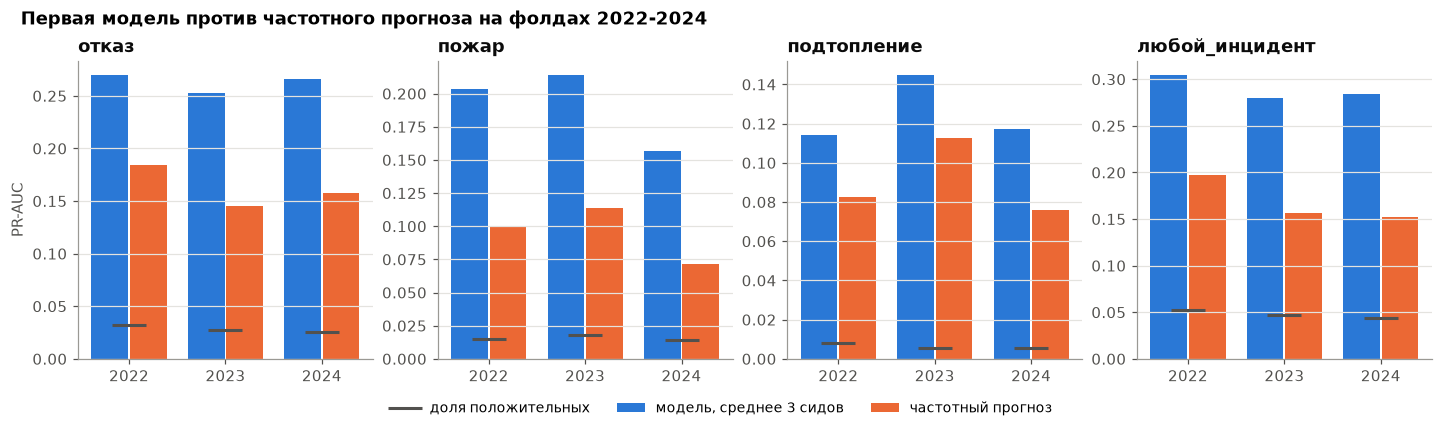

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.8), sharey=False, layout="constrained")
for ax, t in zip(axes, TARGETS):
    d = first[first["цель"] == t]
    x = np.arange(len(d))
    ax.bar(x - 0.2, d["pr_auc_среднего_прогноза"], 0.38, color=ROLE_COLOR["модель"], label="модель, среднее 3 сидов")
    ax.bar(x + 0.2, d["pr_auc_частотного"], 0.38, color=ROLE_COLOR["частотный"], label="частотный прогноз")
    ax.plot(x, d["доля_положительных"], "_", ms=22, mew=2, color=INK2, label="доля положительных")
    ax.set_xticks(x, d["год"])
    ax.set_title(t)
axes[0].set_ylabel("PR-AUC")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, fontsize=9)
fig.suptitle("Первая модель против частотного прогноза на фолдах 2022-2024", x=0.01, ha="left", fontweight="bold")
plt.show()

**Результат.** Модель лучше частотного прогноза во всех 12 парах «цель × год»: подъем PR-AUC среднего
прогноза трех копий к частотному от 1,28 (подтопление, 2023) до 2,20 (пожар, 2024). Например, у отказа 0,269 /
0,252 / 0,266 против 0,185 / 0,146 / 0,158, у любого инцидента 0,304 / 0,280 / 0,284 против 0,198 / 0,156 / 0,152.

**Шум сида.** Стандартное отклонение PR-AUC между тремя копиями у отказа и любого инцидента 0,0018-0,0046, у
пожара 0,0024-0,0088, у подтопления 0,0039-0,0160. Это тысячные и сотые доли PR-AUC, того же порядка, что и типичный
выигрыш от настройки параметров. Отсюда два следствия. Во-первых, сравнивать варианты по одной копии нельзя: разница
в 0,005 может оказаться просто другим сидом. Во-вторых, усреднение копий само по себе полезно: PR-AUC среднего
прогноза трех копий выше средней PR-AUC отдельных копий во всех 12 парах, на +0,0014…+0,0132. Поэтому финальные
модели – среднее пяти копий, а все сравнения на фолдах и валидации – по среднему минимум трех копий.

**Вывод.** Сигнал сверх частотного прогноза есть, и он устойчив по годам. Настраивать параметры имеет смысл, но
выигрыш настройки надо сравнивать с шумом сида.

## 4. Подбор параметров

**Вопрос.** Можно ли заметно улучшить модель параметрами? Подбор – главный источник самообмана: из многих
вариантов лучший на проверке почти всегда немного лучше по случайности, а теперь мы знаем, что одна только смена
сида двигает PR-AUC на величину того же порядка, что и типичный выигрыш настройки. Поэтому каждый набор учим с
тремя сидами и сравниваем средние, а правило выбора строгое и записано до запуска:

- **опорный набор** – параметры из раздела 3;
- набор-кандидат принимается, **только если в каждом из трех фолдов** его средний по сидам PR-AUC выше опорного
  больше чем на два шума сида этого фолда (шум сида – стандартное отклонение PR-AUC между сидами, усредненное по
  всем наборам цели в фолде). Из принятых берем лучший по среднему PR-AUC фолдов; если принятых нет, остаемся с
  опорным;
- число деревьев – медиана лучших итераций выбранного набора по фолдам и сидам.

**Кандидаты различаются по целям.**

- Для отказа и любого инцидента проверяем узкую окрестность одного сильного кандидата (63 листа, от 50 строк в
  листе, шаг 0,03, 70 % признаков на дерево, L1 = 1 и L2 = 10, случайные пороги разбиения `extra_trees`,
  сглаживание листьев): сам кандидат (набор 1) и по одному шагу в стороны (наборы 2-9: 31 и 127 листьев, от 20 и
  от 100 строк в листе, L2 = 3 и 30, доля признаков 0,5 и 0,9); набор 0 – опорный. Это самые частые цели, у них самый маленький шум сида, и
  небольшие, но устойчивые выигрыши здесь можно заметить.
- Для пожара и подтопления – небольшой случайный поиск: 11 случайных наборов из сетки (число листьев 7-63, минимум
  строк в листе 20-400, шаг 0,02-0,05, доля признаков 0,5-0,9, доля строк 0,7-0,9, L2 0-10). Эти цели самые шумные:
  положительных суток в каждом проверочном году всего сотни, и PR-AUC от года к году прыгает сильнее, чем от
  параметров. Правило «лучше в каждом фолде больше чем на два шума сида» особенно важно для подтопления: выигрыш
  внутри шума сида выбирать нельзя.

Каждый набор учим на каждом фолде с ранней остановкой по PR-AUC проверочного года (до 2 000 деревьев, остановка
после 100 деревьев без улучшения). Средний PR-AUC фолдов здесь немного оптимистичен: ранняя остановка смотрела на
тот же проверочный год. Для сравнения наборов между собой это неважно, а честные цифры дадут фолды с
фиксированным числом деревьев ниже, валидация и тест.

In [9]:
C39 = md.PARAMS_CONFIG39
NEAR = [FIRST, C39] + [C39 | d for d in [{"num_leaves": 31}, {"num_leaves": 127}, {"min_data_in_leaf": 20},
                                         {"min_data_in_leaf": 100}, {"lambda_l2": 3.0}, {"lambda_l2": 30.0},
                                         {"feature_fraction": 0.5}, {"feature_fraction": 0.9}]]
SPACE = {"num_leaves": [7, 15, 31, 63], "min_data_in_leaf": [20, 50, 100, 200, 400],
         "learning_rate": [0.02, 0.03, 0.05], "feature_fraction": [0.5, 0.7, 0.9],
         "bagging_fraction": [0.7, 0.9], "lambda_l2": [0.0, 1.0, 10.0]}
rng = np.random.default_rng(42)
RANDOM = [FIRST]
while len(RANDOM) < 12:
    c = {k: rng.choice(v).item() for k, v in SPACE.items()} | {"bagging_freq": 1}
    if c not in RANDOM:
        RANDOM.append(c)
CANDIDATES = {"отказ": NEAR, "любой_инцидент": NEAR, "пожар": RANDOM, "подтопление": RANDOM}

t0 = time.time()
rows = []
for t in TARGETS:
    y = tr[f"цель_{t}"].to_numpy()
    for ci, params in enumerate(CANDIDATES[t]):
        for i_tr, i_va, year in FOLDS:
            for s in SEEDS_CV:
                _, best, ap = md.fit_lgbm_early(Xtr.iloc[i_tr], y[i_tr], Xtr.iloc[i_va], y[i_va], params,
                                                max_rounds=2000, patience=100, seed=s)
                rows.append({"цель": t, "набор": ci, "год": year, "сид": s, "pr_auc": ap, "лучшая_итерация": best})
search = pd.DataFrame(rows)
print(f"{len(search)} обучений с ранней остановкой, {(time.time() - t0) / 60:.1f} мин")

396 обучений с ранней остановкой, 15.1 мин


In [10]:
# шум сида: стандартное отклонение PR-AUC между сидами, среднее по наборам цели в фолде
noise = (search.groupby(["цель", "год", "набор"])["pr_auc"].std(ddof=1)
         .groupby(["цель", "год"]).mean().rename("шум_сида"))
per_fold = search.groupby(["цель", "набор", "год"])["pr_auc"].mean().unstack("год")
gain = per_fold.sub(per_fold.xs(0, level="набор"), level="цель")          # выигрыш к опорному по фолдам
margin = gain.div(2 * noise.unstack("год"), level="цель")                 # выигрыш в единицах «два шума сида»
summary = pd.DataFrame({"pr_auc_среднее": per_fold.mean(axis=1), "выигрыш_средний": gain.mean(axis=1),
                        "выигрыш_мин": gain.min(axis=1), "запас_мин": margin.min(axis=1)})
summary["принят"] = (summary["запас_мин"] > 1) & (summary.index.get_level_values("набор") != 0)

CHOSEN, rows = {}, []
for t in TARGETS:
    s = summary.loc[t].sort_values("pr_auc_среднее", ascending=False)
    ok = s[s["принят"]]
    ci = int(ok.index[0]) if len(ok) else 0
    it = int(search[(search["цель"] == t) & (search["набор"] == ci)]["лучшая_итерация"].median())
    CHOSEN[t] = {"набор": ci, "params": CANDIDATES[t][ci], "n_estimators": it}
    best = int(s.index[0])
    rows.append({"цель": t, "наборов": len(s), "опорный_pr_auc": s.loc[0, "pr_auc_среднее"],
                 "лучший_по_среднему": best, "его_pr_auc": s.loc[best, "pr_auc_среднее"],
                 "его_выигрыш_средний": s.loc[best, "выигрыш_средний"], "его_выигрыш_мин": s.loc[best, "выигрыш_мин"],
                 "два_шума_сида_макс": 2 * noise[t].max(), "его_запас_мин": s.loc[best, "запас_мин"],
                 "принятых": int(s["принят"].sum()), "выбран_набор": ci, "деревьев": it})
choice = pd.DataFrame(rows).set_index("цель")
display((2 * noise).unstack("год").rename(columns=lambda y: f"два_шума_сида_{y}").style.format("{:.4f}"))
display(choice.style.format({c: "{:.4f}" for c in ["опорный_pr_auc", "его_pr_auc", "его_выигрыш_средний",
                                                  "его_выигрыш_мин", "два_шума_сида_макс"]} | {"его_запас_мин": "{:.2f}"}))
display(summary.loc[TARGETS].style.format(
    {"pr_auc_среднее": "{:.4f}", "выигрыш_средний": "{:+.4f}", "выигрыш_мин": "{:+.4f}", "запас_мин": "{:.2f}"}))
display(pd.DataFrame({t: {**CHOSEN[t]["params"], "деревьев": CHOSEN[t]["n_estimators"]} for t in TARGETS})
        .map(lambda v: "–" if pd.isna(v) else v if isinstance(v, bool) else f"{v:g}"))

год,два_шума_сида_2022,два_шума_сида_2023,два_шума_сида_2024
цель,,,
любой_инцидент,0.0022,0.0025,0.0034
отказ,0.0041,0.0041,0.0049
подтопление,0.0148,0.0149,0.0126
пожар,0.0107,0.0062,0.0067


,наборов,опорный_pr_auc,лучший_по_среднему,его_pr_auc,его_выигрыш_средний,его_выигрыш_мин,два_шума_сида_макс,его_запас_мин,принятых,выбран_набор,деревьев
цель,,,,,,,,,,,
отказ,10,0.2914,8,0.2954,0.0039,-0.0017,0.0049,-0.41,0,0,52
пожар,12,0.2167,10,0.2314,0.0147,0.0056,0.0107,0.83,1,6,148
подтопление,12,0.1754,2,0.2060,0.0306,0.0076,0.0149,0.60,0,0,12
любой_инцидент,10,0.3077,6,0.3090,0.0013,0.0000,0.0034,0.00,0,0,110


,отказ,пожар,подтопление,любой_инцидент
num_leaves,31,15,31,31
learning_rate,0.05,0.02,0.05,0.05
min_data_in_leaf,100,50,100,100
feature_fraction,0.8,0.7,0.8,0.8
bagging_fraction,0.8,0.9,0.8,0.8
bagging_freq,1,1,1,1
lambda_l2,0,0,0,0
деревьев,52,148,12,110


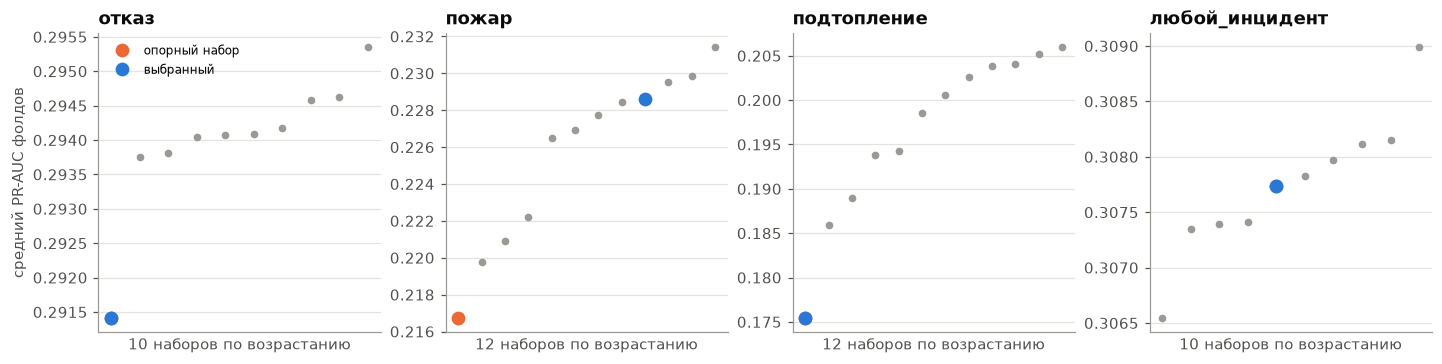

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, t in zip(axes, TARGETS):
    s = summary.loc[t].sort_values("pr_auc_среднее").reset_index()
    ax.plot(s.index, s["pr_auc_среднее"], "o", ms=4, color=GREY)
    for ci, color, lab in [(0, PALETTE[1], "опорный набор"), (CHOSEN[t]["набор"], PALETTE[0], "выбранный")]:
        k = s.index[s["набор"] == ci][0]
        ax.plot(k, s.loc[k, "pr_auc_среднее"], "o", ms=8, color=color, label=lab)
    ax.set_title(t)
    ax.set_xticks([])
    ax.set_xlabel(f"{len(s)} наборов по возрастанию")
axes[0].set_ylabel("средний PR-AUC фолдов")
axes[0].legend(fontsize=8)
plt.show()

**Результат подбора.** Два шума сида в поиске: у отказа 0,0041-0,0049, у любого инцидента 0,0022-0,0034, у
пожара 0,0062-0,0107, у подтопления 0,0126-0,0149 (первая таблица).

- **Отказ.** Все девять кандидатов из окрестности лучше опорного набора по среднему (+0,0023…+0,0039), но ни один
  не проходит правило: в худшем фолде каждый из них хуже опорного (от −0,0001 до −0,0028). Лучший по среднему –
  набор 8 (доля признаков 0,5): 0,2954 против 0,2914 у опорного, запас −0,41. Остаемся с опорным набором, 52 дерева.
  Центральный кандидат (набор 1) дает +0,0028 в среднем и −0,0007 в худшем фолде.
- **Любой инцидент.** Правило не прошел ни один набор. Лучший по среднему – набор 6 (L2 = 3): +0,0013 в среднем и
  +0,0000 в худшем фолде, то есть ничего; остальные хотя бы в одном фолде хуже опорного. Остаемся с опорным, 110
  деревьев.
- **Пожар.** Правило прошел только набор 6 из случайного поиска (15 листьев, шаг 0,02, от 50 строк в листе, 70 %
  признаков и 90 % строк на дерево, без L2): +0,0119 в среднем, +0,0083 в худшем фолде, запас 1,23. Лучший по
  среднему – набор 10 (+0,0147), но в худшем фолде у него только +0,0056 при двух шумах сида до 0,0107 (запас 0,83).
  Выбираем набор 6, 148 деревьев.
- **Подтопление.** Лучший по среднему – набор 2: +0,0306 в среднем, в худшем фолде +0,0076 при двух шумах сида до
  0,0149 (запас 0,60). Выигрыш внутри шума, выбирать его нельзя; остаемся с опорным, 12 деревьев.

Параметры почти ничего не решают: из 40 кандидатов по четырем целям правило прошел один. Зато число деревьев решает
многое: медиана лучших итераций опорного набора – 52 дерева у отказа, 110 у любого инцидента и 12 у подтопления, а
не 500, как в разделе 3.

**Честная цифра фолдов.** Теперь, когда параметры и число деревьев зафиксированы, учим на каждом фолде выбранный
набор с пятью сидами (как будет в финальной модели) без ранней остановки и сравниваем с частотным прогнозом. Эти
же прогнозы 2023 и 2024 годов понадобятся для калибровки и порогов (разделы 7-8): это прогнозы моделей, которые
не видели проверочный год.

In [12]:
t0 = time.time()
FOLD_PRED, rows = {}, []
for t in TARGETS:
    y = tr[f"цель_{t}"].to_numpy()
    for i_tr, i_va, year in FOLDS:
        bag = md.fit_lgbm_seeds(Xtr.iloc[i_tr], y[i_tr], CHOSEN[t]["params"], CHOSEN[t]["n_estimators"],
                                seeds=SEEDS_FINAL)
        p = FOLD_PRED[(t, year)] = md.predict_lgbm(bag, Xtr.iloc[i_va])
        yv = y[i_va]
        rows.append({"цель": t, "год": year, "доля_положительных": yv.mean(), "pr_auc_модели": md.average_precision(yv, p),
                     "pr_auc_частотного": md.average_precision(yv, tr[f"базовый_прогноз_{t}"].to_numpy()[i_va])})
fold_fixed = pd.DataFrame(rows).set_index(["цель", "год"])
fold_fixed["подъем_к_частотному"] = fold_fixed["pr_auc_модели"] / fold_fixed["pr_auc_частотного"]
print(f"фолды выбранных наборов, 5 сидов: {time.time() - t0:.0f} с")
display(fold_fixed.style.format({"доля_положительных": "{:.2%}", "pr_auc_модели": "{:.3f}",
                                 "pr_auc_частотного": "{:.3f}", "подъем_к_частотному": "{:.2f}"}))
display(fold_fixed.groupby("цель", sort=False)[["pr_auc_модели", "pr_auc_частотного"]].mean()
        .style.format("{:.3f}"))

фолды выбранных наборов, 5 сидов: 28 с


,pr_auc_модели,pr_auc_частотного
цель,,
отказ,0.294,0.163
пожар,0.230,0.095
подтопление,0.188,0.090
любой_инцидент,0.309,0.169


**Результат.** С фиксированным числом деревьев и пятью копиями модель на фолдах в 1,65-2,55 раза лучше
частотного прогноза по PR-AUC; в среднем по трем годам отказ 0,294 против 0,163, пожар 0,230 против 0,095,
подтопление 0,188 против 0,090, любой инцидент 0,309 против 0,169. Это заметно выше первой модели раздела 3 при тех
же параметрах: у подтопления в 2022 году 0,175 против 0,114, у отказа 0,305 против 0,269. 500 деревьев с шагом 0,05
переобучались; главный выигрыш подбора – число деревьев и усреднение копий, а не сами параметры.

## 5. Финальная модель и валидация 2025

Обучаем финальные модели на всех рабочих строках 2019-2024 с выбранными параметрами и числом деревьев, каждую – как
среднее пяти копий с сидами 0-4, и впервые смотрим на 2025 год. Для PR-AUC считаем 95 % интервалы обоими
бутстрепами (блоки по 28 суток и объекты) и публикуем более широкий. Главное – интервал **разности** модели и
частотного прогноза на одних и тех же повторных выборках: если он целиком выше нуля, превосходство модели не
случайность отдельных месяцев или объектов.

In [13]:
MODELS, RAW_VA = {}, {}
t0 = time.time()
for t in TARGETS:
    MODELS[t] = md.fit_lgbm_seeds(Xtr, tr[f"цель_{t}"], CHOSEN[t]["params"], CHOSEN[t]["n_estimators"],
                                  seeds=SEEDS_FINAL)
    RAW_VA[t] = md.predict_lgbm(MODELS[t], Xva)
print(f"{len(TARGETS)} финальные модели × {len(SEEDS_FINAL)} сидов на {n(len(tr))} строках 2019-2024: "
      f"{time.time() - t0:.0f} с")
vs = with_const(va).assign(**{f"модель_{t}": RAW_VA[t] for t in TARGETS})


def boot_pair(frame, t, a, b, n_boot=1000):
    """PR-AUC оценок a и b и их разность с 95 % интервалами бутстрепа по блокам 28 суток и по объектам. Один seed –
    одни и те же повторные выборки для всех трех величин, поэтому разность парная. «шире» – интервал, который
    публикуем."""
    y = f"цель_{t}"
    f = frame[["день", "ид_объект", y, a, b]]
    fns = {"модель": lambda g: md.average_precision(g[y], g[a]),
           "частотный": lambda g: md.average_precision(g[y], g[b]),
           "разность": lambda g: md.average_precision(g[y], g[a]) - md.average_precision(g[y], g[b])}
    out = {}
    for name, fn in fns.items():
        blk = md.block_bootstrap(f, fn, block_days=28, n=n_boot, seed=7)
        obj = md.cluster_bootstrap(f, fn, n=n_boot, seed=7)
        wide = ("блоки", blk) if blk[2] - blk[1] >= obj[2] - obj[1] else ("объекты", obj)
        out[name] = {"блоки": blk, "объекты": obj, "шире": wide[1], "шире_по": wide[0]}
    return out


def ci(v):
    return f"{v[0]:.3f} [{v[1]:.3f}; {v[2]:.3f}]"


def ci_table(boots):
    rows = []
    for t, b in boots.items():
        rows.append({"цель": t, **{f"pr_auc_{k}": ci(b[k]["шире"]) for k in ["модель", "частотный"]},
                     "разность_модель_минус_частотный": ci(b["разность"]["шире"]),
                     "разность_блоки_28_суток": ci(b["разность"]["блоки"]),
                     "разность_объекты": ci(b["разность"]["объекты"]),
                     "шире_по": b["разность"]["шире_по"], "разность_выше_нуля": b["разность"]["шире"][1] > 0})
    return pd.DataFrame(rows).set_index("цель")


t0 = time.time()
VAL_BOOT = {t: boot_pair(vs, t, f"модель_{t}", f"базовый_прогноз_{t}") for t in TARGETS}
rows = []
for t in TARGETS:
    for role, col in [("модель (до калибровки)", f"модель_{t}"), ("частотный", f"базовый_прогноз_{t}"),
                      ("константа", f"константа_{t}")]:
        rows.append({"цель": t, "прогноз": role, **scores(vs, t, col)})
val_metrics = pd.DataFrame(rows).set_index(["цель", "прогноз"])
print(f"бутстреп: {time.time() - t0:.0f} с")
display(ci_table(VAL_BOOT))
display(val_metrics.style.format(METRIC_FMT))

4 финальные модели × 5 сидов на 130 104 строках 2019-2024: 13 с


бутстреп: 41 с


,pr_auc_модель,pr_auc_частотный,разность_модель_минус_частотный,разность_блоки_28_суток,разность_объекты,шире_по,разность_выше_нуля
цель,,,,,,,
отказ,0.271 [0.169; 0.365],0.172 [0.099; 0.235],0.099 [0.057; 0.147],0.099 [0.066; 0.129],0.099 [0.057; 0.147],объекты,True
пожар,0.215 [0.141; 0.275],0.132 [0.056; 0.199],0.083 [0.047; 0.121],0.083 [0.060; 0.108],0.083 [0.047; 0.121],объекты,True
подтопление,0.116 [0.072; 0.182],0.062 [0.030; 0.101],0.055 [0.024; 0.120],0.055 [0.024; 0.120],0.055 [0.025; 0.103],блоки,True
любой_инцидент,0.273 [0.198; 0.344],0.183 [0.125; 0.233],0.090 [0.058; 0.129],0.090 [0.062; 0.114],0.090 [0.058; 0.129],объекты,True


**Результат.** Модель лучше частотного прогноза по всем метрикам и для всех целей, и интервалы разности
PR-AUC целиком выше нуля:

| Цель | PR-AUC модели [95 %] | PR-AUC частотного [95 %] | Разность [95 %] | Более широкий интервал разности |
|---|---|---|---|---|
| отказ | 0,271 [0,169; 0,365] | 0,172 [0,099; 0,235] | 0,099 [0,057; 0,147] | по объектам |
| пожар | 0,215 [0,141; 0,275] | 0,132 [0,056; 0,199] | 0,083 [0,047; 0,121] | по объектам |
| подтопление | 0,116 [0,072; 0,182] | 0,062 [0,030; 0,101] | 0,055 [0,024; 0,120] | по блокам 28 суток |
| любой инцидент | 0,273 [0,198; 0,344] | 0,183 [0,125; 0,233] | 0,090 [0,058; 0,129] | по объектам |

Почти везде шире интервал по объектам: результат сильнее зависит от того, какие объекты попали в выборку (несколько
хронически сбоящих объектов дают заметную долю инцидентов), чем от того, какие месяцы. Интервалы самих PR-AUC
широкие (у отказа от 0,17 до 0,37), и это честная неопределенность при 78 объектах; но разность с частотным
прогнозом устойчиво положительна.

В топ-5 суток модель находит пулом 45,4 % отказов (частотный прогноз 38,3 %), 54,4 % пожаров (49,1 %), 77,6 %
подтоплений (69,0 %), 35,9 % любых инцидентов (32,4 %); по суткам соответственно 47,8 %, 59,0 %, 79,0 % и 38,7 %.
Точность топ-5 у отказа 20,4 % против 17,2 %, у любого инцидента 24,6 % против 22,2 %: в пятерке самых рискованных
объектов суток в среднем один дает отказ. Brier модели ниже, чем у частотного прогноза и константы, еще до
калибровки: отказ 0,0256 против 0,0276 и 0,0297, любой инцидент 0,0389 против 0,0417 и 0,0445.

**Период после смены разметки.** 29.10.2025 в журнале сменилась разметка флага тревожности. Цели построены по
тревожным парам «тип датчика + состояние», а не по флагу, но смена разметки совпала с ростом доли инцидентов, а тест
целиком лежит после нее. Проверим отдельно: не ломается ли модель на последних двух месяцах 2025 года.

In [14]:
rows = []
for epoch, g in vs.groupby("эпоха_флага"):
    for t in TARGETS:
        y = g[f"цель_{t}"]
        rows.append({"эпоха_флага": epoch, "цель": t, "строк": len(g), "положительных": int(y.sum()),
                     "доля_положительных": y.mean(),
                     "pr_auc_модели": md.average_precision(y, g[f"модель_{t}"]),
                     "pr_auc_частотного": md.average_precision(y, g[f"базовый_прогноз_{t}"]),
                     "средний_прогноз_модели": g[f"модель_{t}"].mean()})
epoch_val = pd.DataFrame(rows).set_index(["цель", "эпоха_флага"]).sort_index()
epoch_val["подъем_к_частотному"] = epoch_val["pr_auc_модели"] / epoch_val["pr_auc_частотного"]
display(epoch_val.style.format({"доля_положительных": "{:.2%}", "средний_прогноз_модели": "{:.2%}",
                                "pr_auc_модели": "{:.3f}", "pr_auc_частотного": "{:.3f}",
                                "подъем_к_частотному": "{:.2f}"}))

**Результат.** После смены разметки модель не хуже, а лучше: PR-AUC отказа 0,373 против 0,243 до смены,
пожара 0,343 против 0,184, любого инцидента 0,359 против 0,252. Подъем к частотному прогнозу сохраняется (отказ 1,63
до и 1,51 после, пожар 1,64 и 1,62, любой инцидент 1,53 и 1,42). Частотный прогноз после смены тоже точнее (у отказа
0,248 против 0,149): инциденты чаще повторяются на тех же объектах. Доля положительных после смены выше (отказ
3,66 % против 2,93 %), а средний прогноз модели ее занижает (3,24 %). У подтопления после смены всего 11
положительных, и PR-AUC 0,213 на них ненадежен.

**Вывод.** Сдвиг после смены разметки касается уровня вероятностей, а не ранжирования. Модель можно применять
к 2026 году, а уровень должна поправлять калибровка (раздел 7).

## 6. На что опирается модель

**Вопрос.** На чем держится прогноз? Особенно важно, сколько в нем календаря: инциденты в будни случаются в
несколько раз чаще, чем в выходные (раздел 0), и модель может просто выучить «будни = риск», то есть предсказывать
работы бригад, а не состояние объекта.

**Как проверяем.** Три способа:

1. **вклады признаков** – для каждой строки валидации LightGBM раскладывает прогноз (в логитах) на сумму вкладов
   признаков (это SHAP-значения деревьев; у финальной модели – среднее по пяти копиям). Средний модуль вклада,
   сложенный по группам каталога, показывает, какая доля «работы» модели приходится на группу;
2. **абляции** – переобучаем модель без группы признаков и смотрим, сколько теряет PR-AUC валидации. Каждый вариант,
   включая полный, учим с тремя сидами и усредняем прогноз: иначе разница вариантов смешалась бы с шумом сида.
   Выключения: вся история объекта (доли и счетчики эпизодов, часы с последнего эпизода); календарь и контекст
   (выходной, день недели, производственный календарь – праздники, переносы, дни до нерабочего, доля тревог в
   рабочее время, открытия дверей и люков, сезон подтоплений); статичные свойства (сколько у объекта каналов
   каждого типа, пикетов). И обратный опыт – модель только на календаре и статичных свойствах, без какого-либо
   знания о прошлом объекта. Для главного вопроса («сколько дает календарь») считаем интервал разности бутстрепом
   по блокам 28 суток;
3. **будни против выходных** – если модель предсказывает только работы, то внутри выходных (или внутри будней) она
   должна ранжировать объекты не лучше частотного прогноза.

In [15]:
STATIC = [f for f in FEATURES if (f.startswith("каналов_") and not f.endswith("_на_полночь")) or
          f in ("число_пикетов", "есть_температура")]
CALENDAR = GROUP.index[GROUP.isin(["контекст и календарь", "производственный календарь"])].tolist()
HISTORY = GROUP.index[GROUP.isin(["история объекта", "часы с последнего эпизода"])].tolist()
print(f"статичные свойства ({len(STATIC)}): {', '.join(STATIC)}")
print(f"календарь и контекст ({len(CALENDAR)}): {', '.join(CALENDAR)}")
print(f"история объекта: {len(HISTORY)} признаков")

contrib_share, top_feats = {}, {}
for t in TARGETS:
    c = np.abs(md.predict_lgbm(MODELS[t], Xva, pred_contrib=True)[:, :-1]).mean(axis=0)
    s = pd.Series(c, index=FEATURES)
    grp = s.groupby(GROUP.reindex(FEATURES).to_numpy()).sum()
    grp["из них статичные свойства"] = s[STATIC].sum()
    contrib_share[t] = grp / s.sum()
    top_feats[t] = (s / s.sum()).nlargest(8)
display(pd.DataFrame(contrib_share).sort_values("отказ", ascending=False).style.format("{:.1%}"))
display(pd.DataFrame({t: [f"{k} ({v:.0%})" for k, v in top_feats[t].items()] for t in TARGETS}))

статичные свойства (12): каналов_вентилятор, каналов_всего, каналов_дым, каналов_затопление, каналов_ибп, каналов_кд_дверь, каналов_кд_люк, каналов_насос, каналов_ручной_извещатель, каналов_температура, каналов_тепловой, число_пикетов
календарь и контекст (12): выходной, день_недели, доля_тревог_в_рабочее_время_30д, месяц, открытий_дверей_1д, открытий_дверей_7д, открытий_люков_1д, сезон_подтопления, дней_до_нерабочего, нерабочий_день, первый_рабочий_после_выходных, праздник
история объекта: 78 признаков


,отказ,пожар,подтопление,любой_инцидент
история объекта,52.9%,57.5%,57.3%,40.4%
производственный календарь,16.5%,11.2%,6.4%,19.8%
"эпохи, система, соседи, статичные",8.3%,21.3%,14.0%,14.0%
из них статичные свойства,7.6%,20.7%,13.5%,12.6%
каналы,6.7%,1.0%,0.9%,2.3%
контекст и календарь,6.5%,3.5%,3.2%,6.9%
телеметрия,3.4%,0.3%,1.3%,2.1%
связь и активность,2.8%,1.7%,3.3%,4.7%
часы с последнего эпизода,1.8%,3.4%,10.0%,7.9%
насосы,0.6%,0.1%,1.6%,1.2%


,отказ,пожар,подтопление,любой_инцидент
0,доля_дней_отказ_90д (17%),эпизодов_пожар_30д_на_канал (41%),дней_с_последнего_подтопление (33%),дней_до_нерабочего (16%)
1,дней_с_последнего_отказ (16%),каналов_дым (17%),доля_дней_подтопление_90д (15%),доля_дней_любой_инцидент_90д (13%)
2,дней_до_нерабочего (13%),дней_с_последнего_пожар (11%),каналов_насос (12%),часов_с_последнего_любой_инцидент (7%)
3,доля_коротких_отказ_30д (7%),дней_до_нерабочего (9%),часов_с_последнего_подтопление (9%),эпизодов_пожар_30д_на_канал (6%)
4,доля_дней_отказ_30д (4%),часов_с_последнего_пожар (2%),дней_до_нерабочего (5%),дней_с_последнего_любой_инцидент (4%)
5,выходной (3%),нерабочий_день (2%),дней_после_ппр (2%),число_пикетов (4%)
6,нерабочий_день (3%),выходной (2%),выходной (2%),нерабочий_день (4%)
7,доля_дней_отказ_7д (3%),каналов_всего (1%),записей_к_медиане_1д (1%),выходной (4%)


In [16]:
ABLATIONS = {"все признаки": [], "без истории объекта": HISTORY, "без календаря и контекста": CALENDAR,
             "без статичных свойств": STATIC}
t0 = time.time()
rows, ABL_P = [], {}
for t in TARGETS:
    y = tr[f"цель_{t}"]
    variants = {name: [f for f in FEATURES if f not in drop] for name, drop in ABLATIONS.items()}
    variants["только календарь и статичные"] = CALENDAR + STATIC
    for name, cols in variants.items():
        bag = md.fit_lgbm_seeds(Xtr[cols], y, CHOSEN[t]["params"], CHOSEN[t]["n_estimators"], seeds=SEEDS_CV)
        p = ABL_P[(t, name)] = md.predict_lgbm(bag, Xva[cols])
        rows.append({"цель": t, "набор": name, "признаков": len(cols), "pr_auc": md.average_precision(va[f"цель_{t}"], p)})
abl = pd.DataFrame(rows).pivot(index="набор", columns="цель", values="pr_auc")[TARGETS]
abl = abl.loc[list(ABLATIONS) + ["только календарь и статичные"]]
print(f"абляции: {time.time() - t0:.0f} с")
display(abl.style.format("{:.3f}"))
display((abl / abl.loc["все признаки"] - 1).drop(index="все признаки").style.format("{:+.1%}"))

rows = []
for t in TARGETS:
    f = va[["день", "ид_объект", f"цель_{t}"]].assign(a=ABL_P[(t, "все признаки")],
                                                      b=ABL_P[(t, "без календаря и контекста")])
    est, lo, hi = md.block_bootstrap(f, lambda g: md.average_precision(g[f"цель_{t}"], g["a"])
                                     - md.average_precision(g[f"цель_{t}"], g["b"]), block_days=28, n=1000, seed=7)
    rows.append({"цель": t, "вклад_календаря_pr_auc": ci((est, lo, hi))})
display(pd.DataFrame(rows).set_index("цель"))

абляции: 31 с


цель,отказ,пожар,подтопление,любой_инцидент
набор,,,,
все признаки,0.273,0.212,0.119,0.273
без истории объекта,0.190,0.167,0.082,0.208
без календаря и контекста,0.233,0.207,0.114,0.244
без статичных свойств,0.273,0.216,0.119,0.270
только календарь и статичные,0.183,0.129,0.061,0.186


цель,отказ,пожар,подтопление,любой_инцидент
набор,,,,
без истории объекта,-30.4%,-21.4%,-30.5%,-23.9%
без календаря и контекста,-14.7%,-2.4%,-4.3%,-10.8%
без статичных свойств,-0.1%,+1.5%,+0.4%,-1.3%
только календарь и статичные,-33.0%,-39.4%,-48.3%,-31.8%


,вклад_календаря_pr_auc
цель,
отказ,0.040 [0.019; 0.057]
пожар,0.005 [-0.005; 0.015]
подтопление,0.005 [-0.011; 0.028]
любой_инцидент,0.030 [0.013; 0.043]


In [17]:
rows = []
for name, g in vs.groupby(vs["выходной"].map({0: "будни", 1: "выходные"})):
    for t in TARGETS:
        y = g[f"цель_{t}"]
        ap_m, ap_b = md.average_precision(y, g[f"модель_{t}"]), md.average_precision(y, g[f"базовый_прогноз_{t}"])
        rows.append({"цель": t, "сутки": name, "строк": len(g), "положительных": int(y.sum()),
                     "доля_положительных": y.mean(), "pr_auc_модели": ap_m, "подъем_к_доле": ap_m / y.mean(),
                     "pr_auc_частотного": ap_b})
wk = pd.DataFrame(rows).set_index(["цель", "сутки"])
display(wk.style.format({"доля_положительных": "{:.2%}", "pr_auc_модели": "{:.3f}", "подъем_к_доле": "{:.1f}",
                         "pr_auc_частотного": "{:.3f}"}))

,,строк,положительных,доля_положительных,pr_auc_модели,подъем_к_доле,pr_auc_частотного
цель,сутки,,,,,,
отказ,будни,19163,723,3.77%,0.291,7.7,0.218
пожар,будни,19163,372,1.94%,0.229,11.8,0.130
подтопление,будни,19163,99,0.52%,0.126,24.4,0.080
любой_инцидент,будни,19163,1085,5.66%,0.291,5.1,0.216
отказ,выходные,7585,96,1.27%,0.124,9.8,0.065
пожар,выходные,7585,64,0.84%,0.175,20.8,0.179
подтопление,выходные,7585,17,0.22%,0.064,28.8,0.035
любой_инцидент,выходные,7585,164,2.16%,0.158,7.3,0.108


**Результат.**

- **Вклады.** Главное в модели – история объекта: вместе с часами с последнего эпизода 54,7 % вклада у отказа,
  60,9 % у пожара, 67,3 % у подтопления, 48,3 % у любого инцидента. Календарь (контекст и производственный
  календарь вместе) – 23,0 % у отказа и 26,7 % у любого инцидента, 14,7 % у пожара и 9,6 % у подтопления. Признак
  `дней_до_нерабочего` – первый по вкладу у любого инцидента (16 %) и третий у отказа (13 %). У пожара и подтопления
  заметную долю дают статичные свойства (20,7 % и 13,5 %): число дымовых датчиков и насосов определяет, может ли на
  объекте вообще случиться тревога этого класса. Признак `дней_после_ппр` (суток с конца последнего окна ППР АКМ)
  дает 0,1-2,1 % вклада; заметнее всего у подтопления, где он шестой по вкладу (2 %).
- **Абляции.** Без истории объекта PR-AUC падает сильнее всего: подтопление −30,5 %, отказ −30,4 %, любой
  инцидент −23,9 %, пожар −21,4 %. Без календаря и контекста потеря меньше: отказ −14,7 %, любой инцидент −10,8 %,
  подтопление −4,3 %, пожар −2,4 %. Интервал этого вклада (разность PR-AUC, блоки 28 суток) выше нуля у отказа 0,040
  [0,019; 0,057] и любого инцидента 0,030 [0,013; 0,043]; у пожара 0,005 [−0,005; 0,015] и подтопления 0,005
  [−0,011; 0,028] включает ноль. Статичные свойства по отдельности почти ничего не дают (от −1,3 % до +1,5 %): их
  заменяет история. Модель без прошлого объекта (только календарь и статичные свойства) теряет 32-48 %: у отказа
  0,183 против 0,273, почти на уровне частотного прогноза (0,172).
- **Будни и выходные.** Внутри каждого типа суток модель ранжирует объекты лучше частотного прогноза: в выходные у
  отказа 0,124 против 0,065 (подъем к доле положительных 9,8), у любого инцидента 0,158 против 0,108; в будни у
  отказа 0,291 против 0,218. Исключения – пожар в выходные (0,175 против 0,179, ничья на 64 положительных) и
  подтопление в выходные (17 положительных, выводы делать нельзя).

**Вывод.** Календарь в модели есть, и он честный: в будни инцидентов действительно больше, и сервис должен это
учитывать. Но прогноз не сводится к «будни = риск»: календарь дает 2-15 % PR-AUC (уверенно – только у отказа и
любого инцидента), история объекта – 21-31 %, и внутри одного типа суток модель выделяет рискованные объекты.
Ограничение остается: часть «инцидентов» в будни – следы работ, и маска ППР АКМ снимает только работы по метановой
аппаратуре; отличить остальные работы от настоящих угроз без их графика и журнала ОДС нельзя.

## 7. Калибровка

**Наблюдение.** Модель учили на 2019-2024 годах. Средний прогноз финальной модели на валидации: отказ
2,94 % при фактической доле 3,06 %, пожар 1,68 % при 1,63 %, подтопление 0,70 % при 0,43 %, любой инцидент 4,74 %
при 4,67 %. В среднем уровень близок, но у подтопления завышен в 1,6 раза, у отказа занижен. Диспетчеру нужна
вероятность, которой можно верить буквально, поэтому калибруем.

**Как проверяем.** Основной метод – Platt: логистическая функция от логита прогноза, два параметра. Он строго
монотонен, поэтому не меняет порядок объектов (ранжирующие метрики остаются прежними), и ему хватает немногих
положительных. Для сравнения показываем изотоническую регрессию (ступенчатая монотонная функция): она гибче, но
сливает разные объекты в одну вероятность и на малых данных переобучается. Чтобы не оценивать калибратор на тех
же строках, на которых он подогнан, делим валидацию на две половины по чередующимся неделям: подгоняем на одной
половине, проверяем на другой, и наоборот (перекрестная подгонка). Отдельно проверяем вариант, как в сервисе:
Platt, подогнанный на последних 12 месяцах до периода, то есть на прогнозах 2024 года модели, обученной до 2023
года (раздел 4), и примененный к финальной модели на 2025 годе.

In [18]:
def halves(days: pd.Series) -> np.ndarray:
    """Две половины периода по чередующимся неделям от его первого дня."""
    d = pd.to_datetime(days)
    return (((d - d.min()).dt.days // 7) % 2).to_numpy()


HALF_VA = halves(va["день"])
AFTER_VA = (va["эпоха_флага"] == "после смены разметки").to_numpy()
Y24 = {t: tr[f"цель_{t}"].to_numpy()[FOLDS[2][1]] for t in TARGETS}   # проверочный год последнего фолда – 2024


def crossfit(p, y, half, method="Платт", fit_mask=None):
    """Прогноз, откалиброванный «на другой половине»: для недель половины h калибратор подогнан на половине 1 − h
    (и только на строках fit_mask, если задана). Возвращает массив той же длины."""
    out = np.full(len(p), np.nan)
    fit_mask = np.ones(len(p), bool) if fit_mask is None else fit_mask
    for h in (0, 1):
        fit = (half != h) & fit_mask
        out[half == h] = md.Calibrator.fit(p[fit], y[fit], method).predict(p[half == h])
    return out


rows, PROB_VA = [], {}
for t in TARGETS:
    y, p = va[f"цель_{t}"].to_numpy(), RAW_VA[t]
    variants = {"без калибровки": p,
                "Платт, перекрестно по 2025": crossfit(p, y, HALF_VA),
                "изотоническая, перекрестно по 2025": crossfit(p, y, HALF_VA, "изотоническая"),
                "Платт по 2024 (модель до 2023)": md.Calibrator.fit(FOLD_PRED[(t, 2024)], Y24[t], "Платт").predict(p),
                "частотный (для сравнения)": va[f"базовый_прогноз_{t}"].to_numpy()}
    PROB_VA[t] = variants["Платт, перекрестно по 2025"]
    for name, q in variants.items():
        rows.append({"цель": t, "вариант": name, "brier": md.brier(y, q), "pr_auc": md.average_precision(y, q),
                     "средний_прогноз": q.mean(), "доля_положительных": y.mean()})
cal = pd.DataFrame(rows).set_index(["цель", "вариант"])
display(cal.style.format({"brier": "{:.5f}", "pr_auc": "{:.3f}", "средний_прогноз": "{:.2%}",
                          "доля_положительных": "{:.2%}"}))

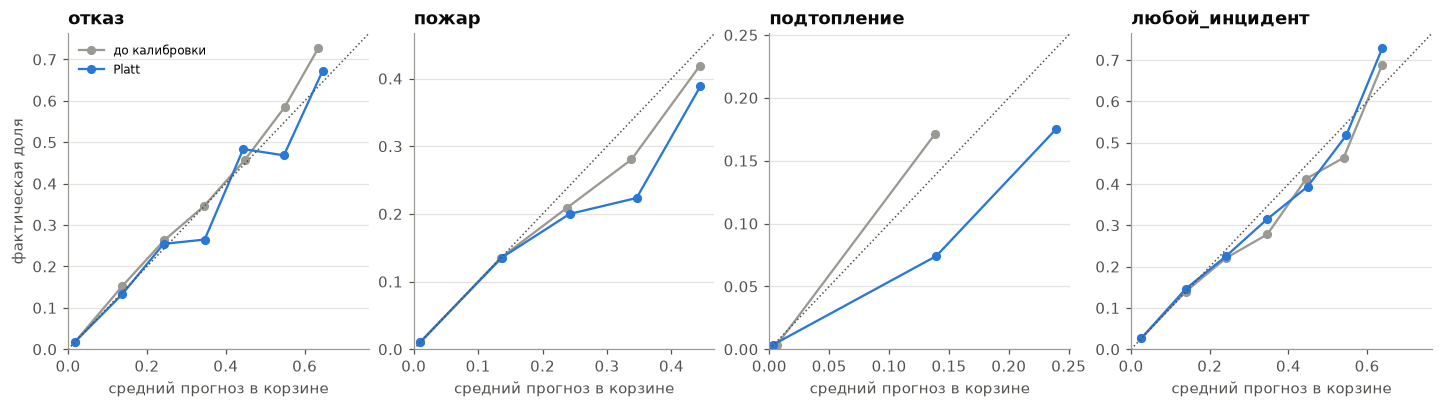

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, t in zip(axes, TARGETS):
    y = va[f"цель_{t}"].to_numpy()
    for q, color, lab in [(RAW_VA[t], GREY, "до калибровки"), (PROB_VA[t], PALETTE[0], "Platt")]:
        r = md.reliability_table(y, q, bins=10)
        r = r[r["количество"] >= 30]
        ax.plot(r["прогноз_средний"], r["доля_фактическая"], "o-", ms=5, color=color, label=lab)
    lim = max(0.05, ax.get_xlim()[1], ax.get_ylim()[1])
    ax.plot([0, lim], [0, lim], ":", color=INK2, lw=1)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim)
    ax.set_title(t)
    ax.set_xlabel("средний прогноз в корзине")
axes[0].set_ylabel("фактическая доля")
axes[0].legend(fontsize=8)
plt.show()

**Результат.** Platt (перекрестно) приводит средний прогноз к фактической доле (отказ 3,06 %, подтопление
0,44 % при 0,43 %) и сохраняет ранжирование (PR-AUC отказа 0,271; у пожара 0,211 против 0,215 без калибровки – две
половины калибруются немного разными функциями). Brier при этом почти не меняется (отказ 0,02554 против 0,02555 без
калибровки, любой инцидент 0,03888 против 0,03890), а у подтопления даже чуть хуже (0,00415 против 0,00406): на
2025 годе модель и так почти откалибрована, и калибровка нужна как страховка от сдвига уровня. Изотоническая
хуже по Brier у трех целей из четырех (у подтопления она лучше всех, 0,00404, но на 116 положительных это разница
в пятом знаке) и портит ранжирование (PR-AUC отказа 0,249, пожара 0,183): ступени сливают разные объекты в одну
вероятность. Вариант, как в сервисе, – Platt на прогнозах 2024 года модели, обученной до 2023, – по Brier почти не
хуже (0,02558 у отказа), но средний уровень у отказа и любого инцидента занижает: 2,71 % при доле 3,06 % и 4,56 %
при 4,67 %. Калибровка годичной давности не успевает за ростом доли; это ограничение нужно помнить и калибровку
обновлять. На графике после калибровки точки в корзинах, где много строк, лежат у диагонали.

**Калибровать ли отдельно на периоде после смены разметки?** Тест целиком лежит после смены 29.10.2025. Калибровка
только на двух последних месяцах точнее по периоду, но опирается на мало примеров. Проверяем на ноябре-декабре
2025: для каждой половины их недель подгоняем Platt (а) на всей валидации без этой половины, (б) только на другой
половине периода после смены – и сравниваем Brier на проверяемой половине. Выигрыш варианта (б) признаем, только
если 95 % интервал разности Brier (бутстреп по объектам) целиком выше нуля; иначе отдельная калибровка – лишняя
сложность.

In [20]:
rows = []
for t in TARGETS:
    y, p = va[f"цель_{t}"].to_numpy(), RAW_VA[t]
    all_cf = crossfit(p, y, HALF_VA)
    after_cf = crossfit(p, y, HALF_VA, fit_mask=AFTER_VA)
    f = va.loc[AFTER_VA, ["день", "ид_объект"]].assign(y=y[AFTER_VA], a=all_cf[AFTER_VA], b=after_cf[AFTER_VA])
    gain_ci = md.cluster_bootstrap(f, lambda g: md.brier(g["y"], g["a"]) - md.brier(g["y"], g["b"]), n=1000, seed=7)
    rows.append({"цель": t, "строк_после": int(AFTER_VA.sum()), "положительных_после": int(y[AFTER_VA].sum()),
                 "доля_после": y[AFTER_VA].mean(), "прогноз_до_калибровки": p[AFTER_VA].mean(),
                 "калибровка_на_всей_валидации": all_cf[AFTER_VA].mean(),
                 "калибровка_на_периоде_после": after_cf[AFTER_VA].mean(),
                 "brier_вся_валидация": md.brier(y[AFTER_VA], all_cf[AFTER_VA]),
                 "brier_только_после": md.brier(y[AFTER_VA], after_cf[AFTER_VA]),
                 "выигрыш_brier_95": f"{gain_ci[0]:+.5f} [{gain_ci[1]:+.5f}; {gain_ci[2]:+.5f}]",
                 "выигрыш_уверенный": gain_ci[1] > 0})
recency = pd.DataFrame(rows).set_index("цель")
display(recency.style.format({c: "{:.2%}" for c in ["доля_после", "прогноз_до_калибровки",
                                                   "калибровка_на_всей_валидации", "калибровка_на_периоде_после"]}
                             | {c: "{:.5f}" for c in ["brier_вся_валидация", "brier_только_после"]}))
CAL_PART = {t: "после смены разметки" if recency.loc[t, "выигрыш_уверенный"] else "последние 12 месяцев"
            for t in TARGETS}
print("на чем калибруем для теста и сервиса:", CAL_PART)

# калибратор для теста и сервиса: Platt на всех 12 месяцах 2025 года (или на периоде после смены, если выигрыш уверенный)
CALS = {}
for t in TARGETS:
    fit = AFTER_VA if CAL_PART[t] == "после смены разметки" else np.ones(len(va), bool)
    CALS[t] = md.Calibrator.fit(RAW_VA[t][fit], va[f"цель_{t}"].to_numpy()[fit], "Платт")

,строк_после,положительных_после,доля_после,прогноз_до_калибровки,калибровка_на_всей_валидации,калибровка_на_периоде_после,brier_вся_валидация,brier_только_после,выигрыш_brier_95,выигрыш_уверенный
цель,,,,,,,,,,
отказ,4748,174,3.66%,3.24%,3.38%,3.74%,0.02820,0.02818,+0.00002 [-0.00038; +0.00061],False
пожар,4748,81,1.71%,1.75%,1.71%,1.75%,0.01365,0.01374,-0.00009 [-0.00031; +0.00013],False
подтопление,4748,11,0.23%,0.63%,0.31%,0.22%,0.00206,0.00207,-0.00001 [-0.00005; +0.00001],False
любой_инцидент,4748,241,5.08%,4.95%,4.88%,5.18%,0.03973,0.03985,-0.00012 [-0.00055; +0.00049],False


на чем калибруем для теста и сервиса: {'отказ': 'последние 12 месяцев', 'пожар': 'последние 12 месяцев', 'подтопление': 'последние 12 месяцев', 'любой_инцидент': 'последние 12 месяцев'}


**Результат.** Отдельная калибровка на ноябре-декабре не дает уверенного выигрыша ни для одной цели: у
отказа Brier 0,02818 против 0,02820 (выигрыш +0,00002, интервал [−0,00038; +0,00061] включает ноль), у любого
инцидента она хуже (−0,00012 [−0,00055; +0,00049]), у пожара и подтопления тоже хуже (−0,00009 и −0,00001).
Средний уровень она поправляет (отказ 3,74 % при доле 3,66 % против 3,38 % у калибровки на всей валидации), но на
174 положительных сутках отказа это не отличается от шума. Поэтому для теста и сервиса калибруем Platt на всех 12
месяцах 2025 года.

**Праздники в будни.** Признак «выходной» видит только субботу и воскресенье: без производственного календаря
модель приняла бы нерабочий будний день (новогодние каникулы, майские, переносы) за рабочий и завысила бы риск.
Теперь в признаках есть производственный календарь. Проверим, совпадает ли средняя откалиброванная вероятность с фактической
долей в рабочие будни, в субботы и воскресенья и в нерабочие будни 2025 года.

In [21]:
dow = va["день"].dt.dayofweek.to_numpy()
day_type = np.where(va["нерабочий_день"].to_numpy() == 1, np.where(dow >= 5, "суббота, воскресенье",
                                                                    "нерабочий будний (праздник, перенос)"),
                    np.where(dow >= 5, "рабочая суббота (перенос)", "рабочий будний"))
rows = []
for name in ["рабочий будний", "суббота, воскресенье", "нерабочий будний (праздник, перенос)"]:
    sel = day_type == name
    for t in ["отказ", "любой_инцидент"]:
        y = va[f"цель_{t}"].to_numpy()[sel]
        rows.append({"сутки": name, "цель": t, "суток": va.loc[sel, "день"].nunique(), "строк": int(sel.sum()),
                     "доля_фактическая": y.mean(), "вероятность_средняя": PROB_VA[t][sel].mean(),
                     "прогноз_к_факту": PROB_VA[t][sel].mean() / y.mean()})
display(pd.DataFrame(rows).set_index(["цель", "сутки"]).style.format(
    {"доля_фактическая": "{:.2%}", "вероятность_средняя": "{:.2%}", "прогноз_к_факту": "{:.2f}"}))

,,суток,строк,доля_фактическая,вероятность_средняя,прогноз_к_факту
цель,сутки,,,,,
отказ,рабочий будний,246,18079,3.92%,3.97%,1.01
любой_инцидент,рабочий будний,246,18079,5.88%,6.09%,1.04
отказ,"суббота, воскресенье",103,7511,1.26%,1.12%,0.88
любой_инцидент,"суббота, воскресенье",103,7511,2.16%,1.64%,0.76
отказ,"нерабочий будний (праздник, перенос)",15,1084,1.38%,1.46%,1.05
любой_инцидент,"нерабочий будний (праздник, перенос)",15,1084,2.03%,2.02%,1.00


**Результат.** Производственный календарь работает: в нерабочие будни (15 суток, 1 084 строки) средняя
вероятность отказа 1,46 % при факте 1,38 % (отношение 1,05), любого инцидента 2,02 % при 2,03 % (1,00). В рабочие
будни отношение прогноза к факту 1,01-1,04. А вот в субботы и воскресенья модель занижает риск: 1,12 % при факте
1,26 % у отказа (0,88) и 1,64 % при 2,16 % у любого инцидента (0,76). Возможное объяснение – калибровка общая для
всех суток, а доля выходных среди инцидентов со временем растет; проверить это можно отдельной калибровкой по типу
суток. Пока вероятности в выходные надо читать как нижнюю оценку; на порядок объектов внутри суток это не влияет.

## 8. Уровни риска с потолком нагрузки

**Задача.** ТЗ оставляет выбор целевых Precision и Recall команде. Диспетчеру непрерывная вероятность неудобна: ему
нужны уровни. Вводим три уровня: «высокий» – объекты, которые стоит проверить сегодня; «средний» – список
наблюдения; «низкий» – все остальное. Главное ограничение для диспетчера – сколько объектов в сутки он физически
может проверить. Поэтому пороги задаем не через желаемую точность, а через **потолок нагрузки**: самый низкий порог
вероятности, при котором ни в одном месяце в среднем в уровень попадает не больше заданного числа объектов в
сутки. Самый низкий – значит максимальная полнота при соблюдении потолка.

Потолки записываем до расчета, исходя из того, что в сутки с данными около 75 объектов, а инцидентов в среднем
несколько в сутки:

| Цель | «Высокий», объектов в сутки | «Высокий» + «средний», объектов в сутки |
|---|---|---|
| отказ | 3 | 8 |
| пожар | 2 | 5 |
| подтопление | 1 | 3 |
| любой инцидент | 5 | 12 |

**Проверка вне выборки.** Порог, подобранный на тех же данных, на которых его проверяют, обещает слишком хорошо.
Поэтому: подбираем пороги на 2024 годе по прогнозам модели, обученной до 2023 года (фолд 2024 из раздела 4; эти
прогнозы калибруем Platt перекрестно по половинам 2024 года), и проверяем на 2025 годе на финальной модели с
перекрестной калибровкой из раздела 7. Нагрузку, точность и полноту (пулом) показываем за весь год и диапазоном
по месяцам: диспетчеру важен не только средний день, но и худший месяц. Для теста и сервиса процедура сдвигается
на год: пороги подбираются на 2025 годе и применяются к 2026.

In [22]:
CAPS = {"отказ": {"высокий": 3, "средний": 8}, "пожар": {"высокий": 2, "средний": 5},
        "подтопление": {"высокий": 1, "средний": 3}, "любой_инцидент": {"высокий": 5, "средний": 12}}
LEVELS = ["высокий", "средний"]


def level(p, th):
    return np.where(p >= th["высокий"], "высокий", np.where(p >= th["средний"], "средний", "низкий"))


def monthly(frame, y_col, p, threshold) -> pd.DataFrame:
    """По месяцам: средняя нагрузка (объектов в сутки с p ≥ порога), точность и полнота пулом."""
    d = pd.DataFrame({"день": frame["день"].to_numpy(), "y": frame[y_col].to_numpy(float),
                      "f": np.asarray(p) >= threshold})
    d["м"] = d["день"].dt.to_period("M")
    d["hit"] = d["y"] * d["f"]
    g = d.groupby("м").agg(помечено=("f", "sum"), суток=("день", "nunique"), попаданий=("hit", "sum"),
                           инцидентов=("y", "sum"))
    return pd.DataFrame({"нагрузка": g["помечено"] / g["суток"],
                         "точность": g["попаданий"] / g["помечено"].where(g["помечено"] > 0),
                         "полнота": g["попаданий"] / g["инцидентов"].where(g["инцидентов"] > 0)})


def rng_str(s, fmt):
    return f"{fmt.format(s.min())}–{fmt.format(s.max())}"


def levels_report(frame, t, p, th) -> pd.DataFrame:
    """Для порогов th по уровням: за весь период (threshold_report) и диапазоны по месяцам."""
    f = frame[["день", f"цель_{t}"]].assign(p=np.asarray(p))
    rows = []
    for lvl in LEVELS:
        r = md.threshold_report(f, f"цель_{t}", "p", th[lvl])
        m = monthly(frame, f"цель_{t}", p, th[lvl])
        rows.append({"цель": t, "уровень": lvl if lvl == "высокий" else "высокий+средний", "порог": r["порог"],
                     "нагрузка_в_сутки": r["нагрузка_в_сутки"], "нагрузка_макс_месяц": r["нагрузка_макс_месяц"],
                     "точность": r["точность"], "полнота": r["полнота"],
                     "нагрузка_по_месяцам": rng_str(m["нагрузка"], "{:.1f}"),
                     "точность_по_месяцам": rng_str(m["точность"], "{:.0%}"),
                     "полнота_по_месяцам": rng_str(m["полнота"], "{:.0%}")})
    return pd.DataFrame(rows)


LVL_FMT = {"порог": "{:.3f}", "нагрузка_в_сутки": "{:.1f}", "нагрузка_макс_месяц": "{:.1f}", "точность": "{:.1%}",
           "полнота": "{:.1%}"}
# прогнозы 2024 года модели, обученной до 2023, с перекрестной калибровкой Platt по половинам 2024 года
fr24 = tr.iloc[FOLDS[2][1]]
HALF_24 = halves(fr24["день"])
PROB_24 = {t: crossfit(FOLD_PRED[(t, 2024)], Y24[t], HALF_24) for t in TARGETS}

TH_DEV, rows_fit, rows_chk = {}, [], []
for t in TARGETS:
    f24 = fr24[["день", f"цель_{t}"]].assign(p=PROB_24[t])
    capped = md.thresholds_with_cap(f24, f"цель_{t}", "p", CAPS[t])
    TH_DEV[t] = {lvl: float(capped.loc[lvl, "порог"]) for lvl in LEVELS}
    rows_fit.append(levels_report(fr24, t, PROB_24[t], TH_DEV[t]))
    rows_chk.append(levels_report(va, t, PROB_VA[t], TH_DEV[t]))
lv_fit = pd.concat(rows_fit).set_index(["цель", "уровень"])
lv_chk = pd.concat(rows_chk).set_index(["цель", "уровень"])
print("пороги, подобранные на 2024 году (прогноз модели, обученной до 2023):")
display(lv_fit.style.format(LVL_FMT))
print("те же пороги на 2025 году (финальная модель, вне выборки):")
display(lv_chk.style.format(LVL_FMT))

пороги, подобранные на 2024 году (прогноз модели, обученной до 2023):


те же пороги на 2025 году (финальная модель, вне выборки):


**Результат проверки вне выборки.** Пороги, подобранные на 2024 годе, на 2025 годе дают почти ту же точность, но
нагрузка в худшем месяце может выйти за потолок:

- отказ, «высокий» (порог 0,154): в 2024 году 2,2 объекта в сутки, худший месяц 3,0; в 2025 году 2,6 в сутки,
  худший месяц 3,4 при потолке 3. Точность 31,2 % (в году подбора 32,2 %), полнота пулом 35,9 % (38,8 %); по
  месяцам 2025 года точность 20-41 %, полнота 21-51 %. Вместе со «средним»: 8,5 объекта в сутки (худший месяц 10,8
  при потолке 8), точность 15,5 %, полнота 58,5 %;
- пожар, «высокий»: 2,1 объекта в сутки, худший месяц 2,6 при потолке 2, точность 19,5 %, полнота 34,2 %; вместе
  со «средним» 4,8 в сутки (худший месяц 5,5), 13,8 % и 55,0 %;
- подтопление, «высокий»: 0,3 объекта в сутки, худший месяц 0,9, точность 19,3 %, полнота 19,0 %, но по месяцам
  от 0 до 46 % и от 0 до 50 %: подтоплений в году всего 116, и помесячные цифры случайны;
- любой инцидент, «высокий»: 3,5 объекта в сутки, худший месяц 4,7 – в пределах потолка 5, точность 30,3 %,
  полнота 31,1 %; вместе со «средним» 10,8 в сутки (худший месяц 12,4 при потолке 12), 18,3 % и 57,5 %.

**Вывод.** Точность уровней вне выборки держится, а нагрузка в худшем месяце может превысить потолок на 3-35 %
(отказ 3,4 при 3 и 10,8 при 8, пожар 2,6 при 2 и 5,5 при 5, любой инцидент 12,4 при 12): когда доля инцидентов
растет, выше того же порога оказывается больше объектов. Обещание заказчику нужно давать с этим запасом.

**Сравнение при одинаковой нагрузке.** Сколько инцидентов нашел бы диспетчер, если бы в те же сутки проверял
столько же объектов, но выбирал их по частотному прогнозу или наугад? Для частотного прогноза в каждые сутки берем
столько же объектов с наибольшей долей инцидентов за 30 суток (при равенстве – меньший ид), для случайного выбора
считаем ожидаемое число попаданий: число проверенных объектов суток × доля объектов с инцидентом в эти сутки.

In [23]:
def same_load(frame, t, flag, base_col) -> dict:
    """Попадания модели (строки flag), частотного прогноза при той же нагрузке в каждые сутки и случайного выбора."""
    y_col = f"цель_{t}"
    f = frame[["день", "ид_объект", y_col, base_col]].assign(_f=np.asarray(flag))
    m = f.groupby("день")["_f"].sum()
    fs = f.sort_values(["день", base_col, "ид_объект"], ascending=[True, False, True], kind="mergesort")
    bflag = fs.groupby("день").cumcount().to_numpy() < fs["день"].map(m).to_numpy()
    per_day = f.groupby("день")[y_col].agg(["size", "sum"])
    total = f[y_col].sum()
    hits = {"модель": f.loc[f["_f"], y_col].sum(), "частотный": fs[y_col].to_numpy()[bflag].sum(),
            "случайно": (m * per_day["sum"] / per_day["size"]).sum()}
    return {"цель": t, "помечено_объекто_суток": int(f["_f"].sum()), "инцидентов_всего": int(total),
            **{f"попаданий_{k}": v for k, v in hits.items()},
            **{f"полнота_{k}": v / total for k, v in hits.items()}}


rows = []
for t in TARGETS:
    rows.append(same_load(va, t, PROB_VA[t] >= TH_DEV[t]["высокий"], f"базовый_прогноз_{t}"))
load_va = pd.DataFrame(rows).set_index("цель")
display(load_va.style.format({"попаданий_модель": "{:.0f}", "попаданий_частотный": "{:.0f}",
                              "попаданий_случайно": "{:.1f}", "полнота_модель": "{:.1%}",
                              "полнота_частотный": "{:.1%}", "полнота_случайно": "{:.1%}"}))

,помечено_объекто_суток,инцидентов_всего,попаданий_модель,попаданий_частотный,попаданий_случайно,полнота_модель,полнота_частотный,полнота_случайно
цель,,,,,,,,
отказ,943,819,294,254,37.2,35.9%,31.0%,4.5%
пожар,766,436,149,125,16.6,34.2%,28.7%,3.8%
подтопление,114,116,22,18,0.8,19.0%,15.5%,0.7%
любой_инцидент,1280,1249,388,351,76.2,31.1%,28.1%,6.1%


**Результат.** При одинаковой нагрузке модель находит больше инцидентов, чем частотный прогноз, и в
разы больше, чем случайный выбор. Из 943 объекто-суток, отмеченных уровнем «высокий» по отказу за 2025 год, отказ
случился в 294 (31 %); частотный прогноз при той же нагрузке нашел бы 254, случайный выбор – около 37. По любому
инциденту 388 попаданий из 1 280 против 351 и 76, по пожару 149 из 766 против 125 и 17, по подтоплению 22 из 114
против 18 и 1. Полнота пулом у отказа 35,9 % против 31,0 % у частотного прогноза и 4,5 % у случайного выбора.

**Пороги для теста и сервиса.** Та же процедура на год позже: подбираем пороги с теми же потолками на 2025 годе
(финальная модель, перекрестная калибровка). Они записываются в конфигурацию и дальше не меняются.

In [24]:
THRESHOLDS, rows = {}, []
for t in TARGETS:
    f25 = va[["день", f"цель_{t}"]].assign(p=PROB_VA[t])
    capped = md.thresholds_with_cap(f25, f"цель_{t}", "p", CAPS[t])
    THRESHOLDS[t] = {lvl: float(capped.loc[lvl, "порог"]) for lvl in LEVELS}
    rows.append(levels_report(va, t, PROB_VA[t], THRESHOLDS[t]))
lv_val = pd.concat(rows).set_index(["цель", "уровень"])
display(lv_val.style.format(LVL_FMT))

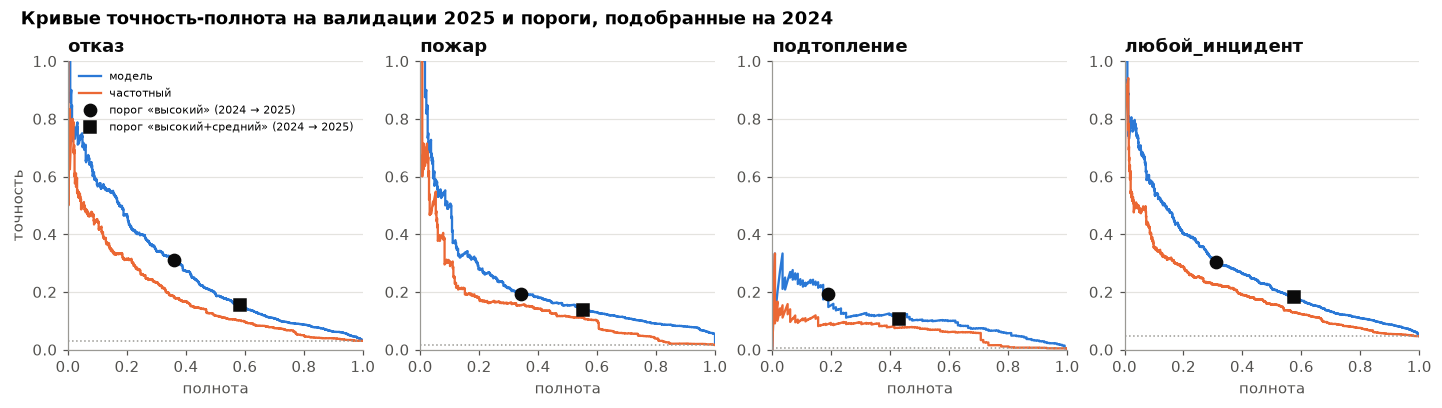

In [25]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, t in zip(axes, TARGETS):
    y = va[f"цель_{t}"].to_numpy()
    for p, color, lab in [(RAW_VA[t], ROLE_COLOR["модель"], "модель"),
                          (va[f"базовый_прогноз_{t}"].to_numpy(), ROLE_COLOR["частотный"], "частотный")]:
        order = np.argsort(-p, kind="mergesort")
        tp = np.cumsum(y[order])
        ax.plot(tp / y.sum(), tp / np.arange(1, len(y) + 1), color=color, label=lab)
    for key, mk in [("высокий", "o"), ("высокий+средний", "s")]:
        r = lv_chk.loc[(t, key)]
        ax.plot(r["полнота"], r["точность"], mk, ms=8, color=INK, label=f"порог «{key}» (2024 → 2025)")
    ax.axhline(y.mean(), ls=":", color=GREY, lw=1)
    ax.set_ylim(0, 1); ax.set_xlim(0, 1)
    ax.set_title(t); ax.set_xlabel("полнота")
axes[0].set_ylabel("точность")
axes[0].legend(fontsize=7)
fig.suptitle("Кривые точность-полнота на валидации 2025 и пороги, подобранные на 2024", x=0.01, ha="left",
             fontweight="bold")
plt.show()

**Вывод.** Пороги для теста и сервиса, подобранные на 2025 годе: отказ – «высокий» от 0,176, «средний»
от 0,070; пожар – 0,156 и 0,070; подтопление – 0,141 и 0,019; любой инцидент – 0,176 и 0,082. На самом 2025 годе они
по построению укладываются в потолки (отказ: 2,1 объекта в сутки в уровне «высокий», точность 33,5 %, полнота
32,0 %; любой инцидент: 3,7, 29,5 % и 32,3 %), но это цифры года подбора. Обещание заказчику – диапазоны проверки
2024 → 2025 выше: на следующем году нагрузка может выйти за потолок, а точность и полнота по месяцам гуляют в
широких пределах. На графике точки порогов лежат на кривой модели, которая почти везде выше кривой частотного
прогноза: при той же полноте модель дает больше точности.

## 9. Газ, потеря связи и неисправность охраны: сглаженная частота

**Постановка.** Для газа, потери связи и неисправности охраны («Состояние охраны: Много неисправных устройств»)
модель не строим. У газа и потери связи во всей валидации 17 и 23 положительных суток на 78 объектов, в тесте 15 и
33; на таком числе примеров нельзя ни подобрать параметры, ни проверить калибровку. У газа после маски ППР АКМ
осталось только 26-42 % положительных суток (раздел 0): большая часть «газа» в журнале – проверки
датчиков тестовым газом, а настоящие срабатывания единичны. Неисправность охраны встречается чаще, но это
общее состояние системы охраны объекта, которое не указывает на конкретное оборудование и плохо прогнозируется на
сутки; сервис показывает ее отдельно как фон и не смешивает с отказом. Для всех трех нужна вероятность по каждому
объекту. Простейшая честная оценка – доля суток с событием на объекте за последний год, сжатая к общей доле:
`(k + s · p0) / (n + s)`, где `k` – суток с событием, `n` – суток с данными за 365 суток строго до `D`, `p0` – общая
доля по всем объектам за то же окно, `s` – сила сжатия. У объекта с короткой историей оценка близка к общей доле, с
длинной – к своей. Силу `s` выбираем по Brier на валидации и сравниваем с частотным прогнозом за 30 суток и с
константой.

**Тонкость: что известно к полуночи.** Цель суток `D − 1` равна 1, если в эти сутки начался эпизод длительностью от
минуты (потеря связи – от 10 минут). Эпизод, начавшийся в 23:59:30, в полночь еще идет, и длинный ли он, станет
известно только после `D 00:00`. Все признаки модели учитывают это: эпизод относится к суткам, когда он стал известен
длинным. А если брать историю прямо из меток целевой, в нее попадут такие эпизоды раньше срока. Посчитаем, сколько
положительных суток затронуто: сравним метку суток `D − 1` с признаком «вчера был длинный эпизод» суток `D`, который
построен по моменту известности (берем пары суток, где обе без маски).

In [26]:
EPS_1D = {"отказ": "эпизодов_отказ_1д", "пожар": "эпизодов_пожар_1д", "подтопление": "эпизодов_подтопление_1д",
          "любой_инцидент": "дней_любой_инцидент_1д", "газ": "эпизодов_газ_1д",
          "неисправность_охраны": "эпизодов_неисправность_охраны_1д", "потеря_связи": "эпизодов_потеря_связи_1д"}
OK = fm["маска"].isna()
same_obj = fm["ид_объект"].eq(fm["ид_объект"].shift(-1))
both_ok = OK & OK.shift(-1, fill_value=False) & same_obj          # сутки D − 1 и D обе без маски
rows = []
for t, col in EPS_1D.items():
    label = fm[f"цель_{t}"]                                        # метка суток D − 1 (эпизод начался в эти сутки)
    known = (fm[col].shift(-1) > 0) & same_obj                     # известно к 00:00 следующих суток
    m = both_ok
    rows.append({"цель": t, "положительных_суток": int(label[m].sum()),
                 "метка_есть_к_полуночи_нет": int((label[m] == 1).sum() - (label[m] & known[m]).sum()),
                 "к_полуночи_есть_метки_нет": int((known[m] & (label[m] == 0)).sum())})
midnight = pd.DataFrame(rows).set_index("цель")
midnight["доля_положительных_суток"] = midnight["метка_есть_к_полуночи_нет"] / midnight["положительных_суток"]
display(midnight.style.format({"доля_положительных_суток": "{:.3%}"}))

,положительных_суток,метка_есть_к_полуночи_нет,к_полуночи_есть_метки_нет,доля_положительных_суток
цель,,,,
отказ,5163,0,0,0.000%
пожар,2574,0,0,0.000%
подтопление,1226,0,0,0.000%
любой_инцидент,8429,1,1,0.012%
газ,209,0,0,0.000%
неисправность_охраны,3505,0,0,0.000%
потеря_связи,416,1,1,0.240%


**Результат.** Для отказа, пожара, подтопления, газа и неисправности охраны расхождений нет ни в одних
сутках из 5 163, 2 574, 1 226, 209 и 3 505 положительных: эпизоды, начавшиеся в последнюю минуту суток, приходятся
на сутки, где у объекта был и другой длинный эпизод того же класса. У потери связи, где порог длительности 10 минут,
расходятся 1 положительные сутки из 416 (0,240 %), у любого инцидента 1 из 8 429 (0,012 %).

**Вывод.** Эффект пренебрежимо мал. Для сглаженной частоты все равно берем историю по моменту известности (вариант
«известно»), а для проверки считаем и вариант прямо по меткам целевой («метка»).

In [27]:
grid_known = fm[KEY + ["маска", "выборка"]].copy()
for t in FREQ:
    # сутки D' в истории: длинный эпизод стал известен в D' (признак «вчера» суток D' + 1); маска суток D' – NaN
    grid_known[f"известно_{t}"] = (fm[EPS_1D[t]].shift(-1) > 0).astype(float).where(OK & same_obj)
    grid_known[f"метка_{t}"] = fm[f"цель_{t}"].astype(float).where(OK)

STRENGTHS = [1, 3, 10, 30, 100, 300, 1000, 3000]
VA_ROWS = (fm["выборка"] == "валидация") & OK
t0 = time.time()
rows, SMOOTH = [], {}
for t in FREQ:
    y = fm.loc[VA_ROWS, f"цель_{t}"].to_numpy()
    for s in STRENGTHS:
        for src in ["известно", "метка"]:
            r = md.smoothed_rate_before(grid_known, f"{src}_{t}", s)
            SMOOTH[(t, s, src)] = r
            rows.append({"цель": t, "сила": s, "история": src, "brier": md.brier(y, r[VA_ROWS]),
                         "pr_auc": md.average_precision(y, r[VA_ROWS])})
freq_search = pd.DataFrame(rows)
print(f"{len(freq_search)} вариантов: {time.time() - t0:.0f} с")
display(freq_search.pivot_table(index="сила", columns=["цель", "история"], values=["brier", "pr_auc"])
        .style.format("{:.5f}"))

48 вариантов: 2 с


**Результат.** Brier почти не зависит от силы сглаживания: у газа 0,00063-0,00064 при любой силе от 1 до
3 000, у неисправности охраны 0,02223-0,02299, у потери связи 0,00086-0,00087. Варианты истории «известно» и «метка»
совпадают до пятого знака, как и следовало из проверки выше. Сравним выбранную сглаженную частоту с частотным
прогнозом за 30 суток и с константой.

In [28]:
STRENGTH = {t: int(freq_search[(freq_search["цель"] == t) & (freq_search["история"] == "известно")]
                   .sort_values("brier").iloc[0]["сила"]) for t in FREQ}
print("сила сглаживания по минимальному Brier на валидации:", STRENGTH)
for t in FREQ:
    fm[f"частота_{t}"] = SMOOTH[(t, STRENGTH[t], "известно")].astype(float)
vf = with_const(fm[VA_ROWS])
rows = []
for t in FREQ:
    for role, col in [("сглаженная частота 365 суток", f"частота_{t}"), ("частотный 30 суток", f"базовый_прогноз_{t}"),
                      ("константа", f"константа_{t}")]:
        rows.append({"цель": t, "прогноз": role, "доля_положительных": vf[f"цель_{t}"].mean(), **scores(vf, t, col),
                     "средний_прогноз": vf[col].mean()})
freq_val = pd.DataFrame(rows).set_index(["цель", "прогноз"])
display(freq_val.style.format(METRIC_FMT | {"средний_прогноз": "{:.2%}"}))

сила сглаживания по минимальному Brier на валидации: {'газ': 1000, 'неисправность_охраны': 30, 'потеря_связи': 1000}


**Результат.** Сила по минимуму Brier: газ 1 000, неисправность охраны 30, потеря связи 1 000. Большая сила у газа
и потери связи значит, что лучшая оценка почти не отличается от общей доли: собственная история объекта добавляет
мало. Ни одна из оценок не предсказывает газ и потерю связи на конкретные сутки: Brier сглаженной частоты у газа
0,0006 – как у константы (0,0006), у частотного прогноза за 30 суток 0,0007; у потери связи все три 0,0009. Что
сглаженная частота делает лучше – отличает объекты, где газ бывает вообще: ROC-AUC 0,745 против 0,551 у частотного
прогноза, полнота пулом в топ-10 64,7 % против 17,6 %; но это 11 суток из 17, и на таком числе цифра очень неточна.
Для неисправности охраны сглаженная частота немного лучше константы по Brier (0,0222 против 0,0232; частотный
0,0226) и по ROC-AUC (0,795 против 0,739 у частотного), но по PR-AUC уступает частотному прогнозу за 30 суток (0,083
против 0,094), а ее средний уровень 1,89 % ниже доли 2,37 %.

**Вывод.** Для газа, потери связи и неисправности охраны сервис показывает фоновую вероятность объекта (сглаженная
частота за год), а не прогноз на завтра. Газ после снятия проверок ППР стал совсем редким (0,06 % суток валидации) и
по-прежнему связан с работами (в будни в 9,6 раза чаще): для его прогноза нужен график и других работ в коллекторе.

## 10. Объяснения прогноза и где искать на объекте

ТЗ требует, чтобы решение принимал человек, а сервис только советовал. Совету без объяснения диспетчер не поверит,
поэтому к каждому прогнозу прикладываем три главные причины. LightGBM раскладывает прогноз строки (в логитах) на
сумму вкладов признаков – это SHAP-значения деревьев, у нашей модели усредненные по пяти копиям. Берем три
признака с наибольшим положительным вкладом, то есть сильнее всего поднявшие риск, и подписываем их смыслом из
каталога и значением признака.

Вторая часть совета – **где искать**. Для отказа сервис ранжирует каналы и пикеты объекта по простому правилу: выше
тот, где отказ был последним (меньше суток с последнего отказа), при равенстве – где отказов больше за 30 суток,
затем меньший ид. Используются только эпизоды, начавшиеся до `D 00:00`. Эпизоды отказа берем те же, из которых
построена цель: длительностью от минуты или незакрытые.

Три реальных случая валидации 2025 для отказа (тест пока не трогаем): самый уверенный верный прогноз уровня
«высокий», инцидент, который модель оценила ниже всех (уровень «низкий»), и самая уверенная ложная тревога.
Уровни – по порогам для сервиса из раздела 8.

In [29]:
def pairs_classes(path):
    """Классы эпизодов в каталоге кэша (читаем только столбец класса)."""
    return set(ds.dataset(path, format="parquet").to_table(columns=["класс"]).column("класс").unique().to_pylist())


# Действующий кэш эпизодов тревог: все классы целей текущего словаря есть, лишних классов нет
CURRENT = [d for d in sorted(glob.glob(str(PROCESSED_DIR / "episodes" / "alarms_pairs_*")))
           if set(ep.TARGET_CLASSES) <= pairs_classes(d) <= set(ep.PRIORITY)]
assert len(CURRENT) == 1, CURRENT
eps = agg.read_vitrine(CURRENT[0])[["ид_канала_данных", "ид_объект", "пикет", "начало", "длительность_с", "класс"]]
dur = pd.to_numeric(eps["длительность_с"], errors="coerce")
EPS_FAULT = eps[(eps["класс"] == "отказ") & (dur.isna() | (dur >= 60))].reset_index(drop=True)
channels = agg.read_vitrine(PROCESSED_DIR / "channels.parquet")
print(f"эпизодов отказа от минуты: {n(len(EPS_FAULT))}; каналов в справочнике: {n(len(channels))}")

T_EXPL = "отказ"
lv = level(PROB_VA[T_EXPL], THRESHOLDS[T_EXPL])
cand = va.assign(вероятность=PROB_VA[T_EXPL], уровень=lv)
y = cand[f"цель_{T_EXPL}"]
cases = {
    "верный высокий прогноз": cand[(cand["уровень"] == "высокий") & (y == 1)].nlargest(1, "вероятность"),
    "пропущенный инцидент": cand[(cand["уровень"] == "низкий") & (y == 1)].nsmallest(1, "вероятность"),
    "ложная тревога": cand[(cand["уровень"] == "высокий") & (y == 0)].nlargest(1, "вероятность"),
}
for name, row in cases.items():
    r = md.top_reasons(MODELS[T_EXPL], row[FEATURES], MEANING, k=3)[0]
    rr = row.iloc[0]
    D = rr["день"]
    print(f"{name}: объект {rr['ид_объект']}, сутки {D:%Y-%m-%d}, вероятность отказа {rr['вероятность']:.1%}, "
          f"уровень «{rr['уровень']}», факт {int(rr[f'цель_{T_EXPL}'])}")
    for i, item in enumerate(r, 1):
        print(f"   {i}. {item['смысл']} = {item['значение']:g} (вклад в логит {item['вклад']:+.2f})")
    if not r:
        print("   ни один признак не поднял риск выше среднего")
    top_ch = loc.rank_channels(EPS_FAULT, rr["ид_объект"], D, k=3)
    top_pk = loc.rank_channels(EPS_FAULT, rr["ид_объект"], D, k=3, level="пикет")
    print("   где искать, каналы: " + ("; ".join(
        f"{c.ид_канала_данных} (пикет {c.пикет:g}, {c.дней_с_последнего} сут. с отказа, {c.дней_с_отказом_30д} сут. "
        f"с отказом за 30)" for c in top_ch.itertuples()) or "истории отказов нет"))
    print("   где искать, пикеты: " + (", ".join(f"{p:g}" for p in top_pk["пикет"]) or "истории отказов нет"))
    fact = EPS_FAULT[(EPS_FAULT["ид_объект"] == rr["ид_объект"]) & (EPS_FAULT["начало"] >= D)
                     & (EPS_FAULT["начало"] < D + pd.Timedelta(days=1))].sort_values("начало")
    if len(fact):
        print(f"   факт: первый отказ суток на канале {fact.iloc[0]['ид_канала_данных']} "
              f"(пикет {fact.iloc[0]['пикет']:g}) в {fact.iloc[0]['начало']:%H:%M}")

эпизодов отказа от минуты: 759 653; каналов в справочнике: 11 485
верный высокий прогноз: объект 5962, сутки 2025-12-04, вероятность отказа 77.9%, уровень «высокий», факт 1
   1. суток с последних суток, когда был длинный эпизод класса «отказ» (3 650 – не было) = 1 (вклад в логит +1.08)
   2. доля суток с длинным эпизодом класса «отказ» среди суток окна без маски, окно 7 сут. = 1 (вклад в логит +0.76)
   3. доля суток с длинным эпизодом класса «отказ» среди суток окна без маски, окно 90 сут. = 1 (вклад в логит +0.58)
   где искать, каналы: 334755 (пикет 1176, 1 сут. с отказа, 4 сут. с отказом за 30); 334757 (пикет 1178, 1 сут. с отказа, 2 сут. с отказом за 30); 334512 (пикет 1050, 2 сут. с отказа, 2 сут. с отказом за 30)
   где искать, пикеты: 1176, 1178, 1050
   факт: первый отказ суток на канале 334755 (пикет 1176) в 03:25
пропущенный инцидент: объект 5583, сутки 2025-07-05, вероятность отказа 0.3%, уровень «низкий», факт 1
   1. длинных эпизодов класса «пожар» за 30 суток на канал т

**Что видим.** Верный прогноз (объект 5962, 04.12.2025, 77,9 %) и ложная тревога (тот же объект 5962 две
недели спустя, 17.12.2025, 73,5 %) объясняются одинаково: последний отказ на объекте был накануне, доля суток с
отказом за 7 суток равна 1, за 90 суток 1 и 0,94. Это хронически сбоящий объект, и в редкие спокойные сутки модель
дает ложную тревогу: по журналу датчиков нельзя понять, что сбой устранили. Диспетчеру такая причина понятна и
полезна сама по себе: объект с отказами каждый день – кандидат на ремонт, а не на ежедневную проверку. Для верного
прогноза список «где искать» сработал точно: первым в нем стоит канал 334755 (пикет 1176), отказывавший накануне и
в 4 сутках из последних 30, и именно на нем в 03:25 начался отказ.

Пропущенный инцидент (объект 5583, 05.07.2025, 0,3 %) выглядит иначе: все вклады ничтожны (самый большой +0,02),
последний отказ на объекте был 698 суток назад. Такой внезапный отказ по журналу не предсказать; при этом
единственный канал в списке «где искать», 268863, и оказался местом отказа.

Насколько типичны такие пропуски, посчитаем по всем отказам валидации.

In [30]:
miss = cand[(cand["уровень"] == "низкий") & (y == 1)]
print(f"отказов в валидации: {int(y.sum())}, из них на уровне «низкий»: {len(miss)}; у пропущенных "
      f"за 90 суток не было ни одних суток с отказом: {(miss['доля_дней_отказ_90д'] == 0).mean():.0%} "
      f"(у всех отказов валидации: {(cand.loc[y == 1, 'доля_дней_отказ_90д'] == 0).mean():.0%})")
high = cand["уровень"] == "высокий"
top1 = [x[0]["признак"] if x else None for x in md.top_reasons(MODELS[T_EXPL], cand.loc[high, FEATURES], MEANING, 3)]
t1 = pd.Series(top1).map(GROUP).value_counts(normalize=True).rename("доля_главной_причины")
print(f"прогнозов уровня «высокий» в валидации: {int(high.sum())}; группа главной причины:")
display(t1.to_frame().style.format("{:.1%}"))

отказов в валидации: 819, из них на уровне «низкий»: 388; у пропущенных за 90 суток не было ни одних суток с отказом: 17% (у всех отказов валидации: 8%)
прогнозов уровня «высокий» в валидации: 782; группа главной причины:


,доля_главной_причины
история объекта,100.0%


**Результат.** Из 819 отказов валидации 388 модель оставила на уровне «низкий»: пороги с потолком
нагрузки жесткие, уровни «высокий» и «средний» по отказу вместе – не больше 8 объектов в сутки. У 17 % пропущенных
за 90 суток не было ни одних суток с отказом (среди всех отказов валидации таких 8 %): внезапные отказы «с нуля» –
заметная, но не главная часть пропусков, а большинство пропусков – объекты, где отказы бывали, но в эти сутки риск
оказался ниже порога.

**Проверка здравого смысла.** У всех 782 прогнозов уровня «высокий» главная причина – признак истории объекта
(доли суток и счетчики эпизодов, сутки с последнего отказа). Это согласуется с абляцией: без истории PR-AUC отказа
падает на 30 %. Календарь дает около пятой части вклада (раздел 6), но поднимает риск всем объектам в будни
одинаково, а какой объект окажется наверху списка, решает его история.

**Вывод.** Причины понятны диспетчеру и честно показывают, на чем держится прогноз. Они хранятся в журнале прогнозов
вместе с вероятностью.

**Насколько хорошо правило «где искать».** Для каждых суток валидации с отказом находим канал, на котором отказ
начался первым, и проверяем, попал ли он в первую строчку (hit@1) или в первые три (hit@3) списка сервиса. То же
для пикета. Сравниваем со случайным выбором: если бы диспетчер брал k каналов объекта наугад, он попал бы с
вероятностью k / (число каналов объекта в справочнике); более строгий ориентир – наугад среди каналов, на которых
отказы уже бывали. Отдельно – мягкий вариант: в списке есть хотя бы один канал, на котором в эти сутки начинался
отказ (в сутки с отказом их бывает несколько, и проверка любого из них диспетчеру полезна).

In [31]:
fault_rows = va.loc[va[f"цель_{T_EXPL}"] == 1, KEY]
fe = EPS_FAULT.assign(день=EPS_FAULT["начало"].dt.floor("D")).sort_values("начало", kind="mergesort")
first_fault = fe.drop_duplicates(KEY)[KEY + ["ид_канала_данных", "пикет"]]
ff = fault_rows.merge(first_fault, on=KEY, how="left")
print(f"суток с отказом: {len(ff)}, первый эпизод найден: {ff['ид_канала_данных'].notna().mean():.1%}")
t0 = time.time()
ff["каналы"] = loc.rank_grid(EPS_FAULT, ff[KEY], k=3, level="канал").to_numpy()
ff["пикеты"] = loc.rank_grid(EPS_FAULT, ff[KEY], k=3, level="пикет").to_numpy()
print(f"ранжирование: {time.time() - t0:.0f} с")
n_ch = channels.groupby("ид_объект")["ид_канала_данных"].nunique()
n_pk = channels.dropna(subset=["пикет"]).groupby("ид_объект")["пикет"].nunique()
# каналы с отказом до D – знаменатель строгого случайного ориентира
hist_n = (fe.groupby(["ид_объект", "ид_канала_данных"])["день"].min().rename("первый").reset_index())
ff["каналов_с_историей"] = [int(((hist_n["ид_объект"] == o) & (hist_n["первый"] < d)).sum())
                            for o, d in zip(ff["ид_объект"], ff["день"])]
day_set = fe.groupby(KEY)["ид_канала_данных"].agg(set).rename("каналы_суток").reset_index()
ff = ff.merge(day_set, on=KEY, how="left")


def p_any(N, m, k):
    """Вероятность, что среди k каналов, взятых наугад из N, есть хотя бы один из m."""
    miss = np.ones(len(N))
    for i in range(k):
        miss *= np.clip((N - m - i) / (N - i), 0, 1)
    return 1 - miss


rows = []
for k in (1, 3):
    hit_any = [bool(s & {x["ид_канала_данных"] for x in lst[:k]}) for s, lst in zip(ff["каналы_суток"], ff["каналы"])]
    rnd_any = p_any(ff["ид_объект"].map(n_ch).to_numpy(float), ff["каналы_суток"].str.len().to_numpy(float), k).mean()
    hit_ch = [c in [x["ид_канала_данных"] for x in lst[:k]] for c, lst in zip(ff["ид_канала_данных"], ff["каналы"])]
    hit_pk = [p in [x["пикет"] for x in lst[:k]] for p, lst in zip(ff["пикет"], ff["пикеты"])]
    rnd_all = np.minimum(k / ff["ид_объект"].map(n_ch), 1).mean()
    rnd_hist = np.where(ff["каналов_с_историей"] > 0, np.minimum(k / ff["каналов_с_историей"].clip(lower=1), 1), 0).mean()
    rnd_pk = np.minimum(k / ff["ид_объект"].map(n_pk), 1).mean()
    rows.append({"k": k, "канал_правило": np.mean(hit_ch), "канал_наугад_среди_всех": rnd_all,
                 "канал_наугад_среди_отказывавших": rnd_hist, "любой_канал_суток_правило": np.mean(hit_any),
                 "любой_канал_суток_наугад": rnd_any, "пикет_правило": np.mean(hit_pk),
                 "пикет_наугад": rnd_pk})
loc_hits = pd.DataFrame(rows).set_index("k")
print(f"суток, когда у объекта нет ни одного канала с отказом в прошлом: {(ff['каналы'].str.len() == 0).mean():.1%}; "
      f"каналов на объект в справочнике: медиана {n_ch.median():.0f}; каналов с отказом в сутки с отказом: "
      f"медиана {ff['каналы_суток'].str.len().median():.0f}, в среднем {ff['каналы_суток'].str.len().mean():.1f}")
display(loc_hits.style.format("{:.1%}"))

суток с отказом: 819, первый эпизод найден: 100.0%


ранжирование: 0 с
суток, когда у объекта нет ни одного канала с отказом в прошлом: 0.5%; каналов на объект в справочнике: медиана 66; каналов с отказом в сутки с отказом: медиана 1, в среднем 5.5


,канал_правило,канал_наугад_среди_всех,канал_наугад_среди_отказывавших,любой_канал_суток_правило,любой_канал_суток_наугад,пикет_правило,пикет_наугад
k,,,,,,,
1,21.1%,3.4%,10.1%,33.8%,6.1%,21.2%,11.0%
3,37.2%,10.1%,24.3%,51.3%,16.9%,39.3%,23.4%


**Результат.** Правило «где искать» в несколько раз лучше случайного выбора. Канал, где отказ начался
первым, стоит первым в списке в 21,1 % суток с отказом и входит в первую тройку в 37,2 %; наугад среди всех каналов
объекта (медиана 66 каналов) – 3,4 % и 10,1 %, наугад среди каналов, которые уже отказывали, – 10,1 % и 24,3 %.
Хотя бы один канал с отказом этих суток стоит первым в 33,8 % случаев и входит в тройку в 51,3 % (наугад 6,1 % и
16,9 %): в сутки с отказом начинается отказ в среднем на 5,5 каналах (медиана 1, то есть бывают массовые сутки).
Пикет, где начался первый отказ, первый в списке в 21,2 % суток и в тройке в 39,3 % (наугад 11,0 % и 23,4 %). В
0,5 % суток с отказом у объекта раньше не отказывал ни один канал, и список пуст.

**Вывод.** Список «где искать» – подсказка, а не точная локация: примерно в половине суток с отказом хотя бы один
канал из первой тройки действительно отказывает, это втрое чаще случайной проверки. Для более точной локации нужны
данные о ремонтах и заменах оборудования по каналам.

## 11. Тест 2026: один проход

Все решения зафиксированы: параметры, число деревьев и 5 сидов (раздел 4), калибровка Platt на 2025 годе
(раздел 7), пороги уровней с потолками нагрузки, подобранные на 2025 годе (раздел 8), сила сглаживания для газа,
потери связи и неисправности охраны (раздел 9), правило «где искать» (раздел 10). Одна ячейка ниже применяет их к
первому полугодию 2026 года и считает все метрики; следующие ячейки только показывают результат. Напомним статус
теста (раздел 2): период уже просматривался предыдущими версиями цепочки, поэтому цифры ниже – проверка решений,
принятых по фолдам и валидации, но не оценка на совсем нетронутом периоде.

In [32]:
# Все решения зафиксированы выше. Эта ячейка – единственное место, где на тест смотрят модели.
DECISIONS = {t: {"набор": CHOSEN[t]["набор"], "деревьев": CHOSEN[t]["n_estimators"], "сидов": len(SEEDS_FINAL),
                 "калибровка": "Платт", "калибровка_на": CAL_PART[t],
                 **{f"порог_{k}": v for k, v in THRESHOLDS[t].items()},
                 **{f"потолок_{k}": v for k, v in CAPS[t].items()}} for t in TARGETS}
display(pd.DataFrame(DECISIONS))

t0 = time.time()
RAW_TE = {t: md.predict_lgbm(MODELS[t], Xte) for t in TARGETS}
PROB_TE = {t: CALS[t].predict(RAW_TE[t]) for t in TARGETS}
ts = with_const(te).assign(**{f"модель_{t}": RAW_TE[t] for t in TARGETS},
                           **{f"вероятность_{t}": PROB_TE[t] for t in TARGETS})
TE_ROWS = (fm["выборка"] == "тест") & OK
for t in FREQ:
    ts[f"частота_{t}"] = fm.loc[TE_ROWS, f"частота_{t}"].to_numpy()

TEST_BOOT = {t: boot_pair(ts, t, f"модель_{t}", f"базовый_прогноз_{t}") for t in TARGETS}
rows = []
for t in TARGETS:
    for role, col, prob in [("модель", f"модель_{t}", f"вероятность_{t}"), ("частотный", f"базовый_прогноз_{t}", None),
                            ("константа", f"константа_{t}", None)]:
        rows.append({"цель": t, "прогноз": role, "доля_положительных": ts[f"цель_{t}"].mean(),
                     **scores(ts, t, col, prob)})
for t in FREQ:
    for role, col in [("сглаженная частота 365 суток", f"частота_{t}"), ("частотный 30 суток", f"базовый_прогноз_{t}"),
                      ("константа", f"константа_{t}")]:
        rows.append({"цель": t, "прогноз": role, "доля_положительных": ts[f"цель_{t}"].mean(), **scores(ts, t, col)})
test_metrics = pd.DataFrame(rows).set_index(["цель", "прогноз"])
test_levels = pd.concat([levels_report(ts, t, PROB_TE[t], THRESHOLDS[t]) for t in TARGETS]).set_index(["цель", "уровень"])
test_load = pd.DataFrame([same_load(ts, t, PROB_TE[t] >= THRESHOLDS[t]["высокий"], f"базовый_прогноз_{t}")
                          for t in TARGETS]).set_index("цель")
test_reliab = {t: md.reliability_table(ts[f"цель_{t}"], PROB_TE[t], bins=10) for t in TARGETS}
test_month = pd.DataFrame({t: ts.groupby(ts["день"].dt.to_period("M")).apply(
    lambda g, t=t: pd.Series({"модель": md.average_precision(g[f"цель_{t}"], g[f"модель_{t}"]),
                              "частотный": md.average_precision(g[f"цель_{t}"], g[f"базовый_прогноз_{t}"]),
                              "доля": g[f"цель_{t}"].mean()})).stack() for t in TARGETS})
print(f"тест посчитан за {time.time() - t0:.0f} с; строк {n(len(ts))}")

,отказ,пожар,подтопление,любой_инцидент
набор,0,6,0,0
деревьев,52,148,12,110
сидов,5,5,5,5
калибровка,Платт,Платт,Платт,Платт
калибровка_на,последние 12 месяцев,последние 12 месяцев,последние 12 месяцев,последние 12 месяцев
порог_высокий,0.1765,0.1563,0.1408,0.1765
порог_средний,0.0696,0.0699,0.0190,0.0820
потолок_высокий,3,2,1,5
потолок_средний,8,5,3,12


тест посчитан за 23 с; строк 13 651


In [33]:
display(ci_table(TEST_BOOT))
display(test_metrics.style.format(METRIC_FMT))

,pr_auc_модель,pr_auc_частотный,разность_модель_минус_частотный,разность_блоки_28_суток,разность_объекты,шире_по,разность_выше_нуля
цель,,,,,,,
отказ,0.316 [0.196; 0.408],0.216 [0.096; 0.293],0.100 [0.050; 0.134],0.100 [0.050; 0.134],0.100 [0.073; 0.131],блоки,True
пожар,0.279 [0.163; 0.368],0.174 [0.073; 0.238],0.106 [0.063; 0.149],0.106 [0.075; 0.155],0.106 [0.063; 0.149],объекты,True
подтопление,0.194 [0.073; 0.308],0.084 [0.027; 0.116],0.110 [0.034; 0.213],0.110 [0.079; 0.156],0.110 [0.034; 0.213],объекты,True
любой_инцидент,0.375 [0.257; 0.479],0.278 [0.163; 0.360],0.097 [0.077; 0.128],0.097 [0.079; 0.118],0.097 [0.077; 0.128],объекты,True


**Результат.** На тесте модель лучше частотного прогноза для всех четырех целей, и интервал разности
PR-AUC везде целиком выше нуля (более широкий из двух бутстрепов: у разности отказа – по блокам 28 суток, у
остальных – по объектам):

| Цель | PR-AUC модели [95 %] | PR-AUC частотного [95 %] | Разность [95 %] | Доля положительных |
|---|---|---|---|---|
| отказ | 0,316 [0,196; 0,408] | 0,216 [0,096; 0,293] | 0,100 [0,050; 0,134] | 4,26 % |
| пожар | 0,279 [0,163; 0,368] | 0,174 [0,073; 0,238] | 0,106 [0,063; 0,149] | 2,01 % |
| подтопление | 0,194 [0,073; 0,308] | 0,084 [0,027; 0,116] | 0,110 [0,034; 0,213] | 0,65 % |
| любой инцидент | 0,375 [0,257; 0,479] | 0,278 [0,163; 0,360] | 0,097 [0,077; 0,128] | 6,42 % |

У подтопления, как и ожидалось при 89 положительных сутках, интервалы самые широкие: PR-AUC модели от 0,07 до 0,31,
разность с частотным прогнозом от 0,03 до 0,21. Превосходство над частотным прогнозом есть, но его величину по
полугодию теста назвать нельзя.

Топ-5 суток, точность / полнота по суткам / полнота пулом: отказ 26,3 % / 43,0 % / 40,8 % (частотный прогноз
22,1 % / 36,0 % / 34,3 %), пожар 17,6 % / 59,8 % / 57,5 % (16,4 % / 54,5 % / 53,8 %), подтопление 7,8 % / 79,9 % /
78,7 % (7,0 % / 73,8 % / 70,8 %), любой инцидент 37,2 % / 41,3 % / 38,2 % (33,1 % / 35,9 % / 34,0 %). Brier модели
ниже, чем у частотного прогноза и константы: отказ 0,0341 против 0,0370 и 0,0409, пожар 0,0167 против 0,0179 и
0,0198, подтопление 0,0059 против 0,0063 и 0,0065, любой инцидент 0,0488 против 0,0527 и 0,0603.

PR-AUC на тесте выше, чем на валидации (отказ 0,316 против 0,271, любой инцидент 0,375 против 0,273). Это не признак
утечки: частотный прогноз вырос так же (у отказа 0,216 против 0,172), доля положительных выше (4,26 % против
3,06 %), а на ноябре-декабре 2025 года, после смены разметки, PR-AUC модели отказа был уже 0,373. Разность с
частотным прогнозом на тесте (0,100 у отказа) почти та же, что на валидации (0,099).

Газ, потеря связи и неисправность охраны: Brier сглаженной частоты у газа 0,0011 – как у частотного прогноза и
константы (15 положительных суток за полугодие), у потери связи 0,0024 против 0,0023 у частотного и 0,0024 у
константы, у неисправности охраны 0,0157 против 0,0163 и 0,0170 (по PR-AUC 0,125 против 0,101 у частотного). Вывод
раздела 9 подтверждается: это фоновая вероятность, а не прогноз.

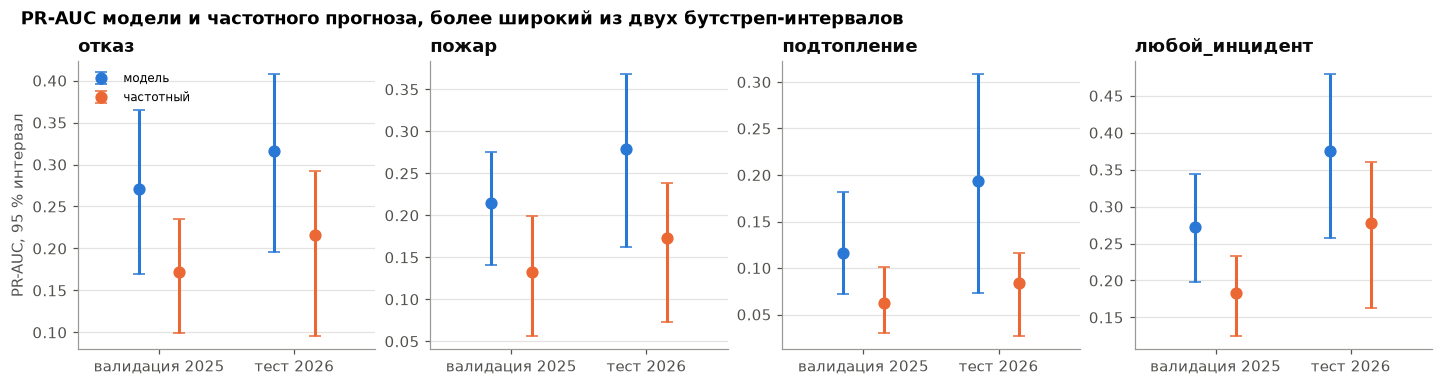

In [34]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, t in zip(axes, TARGETS):
    for i, (split, boot) in enumerate([("валидация", VAL_BOOT[t]), ("тест", TEST_BOOT[t])]):
        for j, role in enumerate(["модель", "частотный"]):
            est, lo, hi = boot[role]["шире"]
            x = i + (j - 0.5) * 0.3
            ax.errorbar(x, est, yerr=[[est - lo], [hi - est]], fmt="o", ms=7, capsize=4, lw=2,
                        color=ROLE_COLOR[role], label=role if i == 0 else None)
    ax.set_xticks([0, 1], ["валидация 2025", "тест 2026"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_title(t)
axes[0].set_ylabel("PR-AUC, 95 % интервал")
axes[0].legend(fontsize=8)
fig.suptitle("PR-AUC модели и частотного прогноза, более широкий из двух бутстреп-интервалов", x=0.01, ha="left",
             fontweight="bold")
plt.show()

Выполняются ли обещания уровней риска? Сравниваем тест с проверкой вне выборки на 2025 годе (раздел 8) и
смотрим, сколько инцидентов уровень «высокий» нашел по сравнению с частотным прогнозом и случайным выбором при той
же нагрузке.

In [35]:
display(pd.concat({"2024 → 2025 (проверка)": lv_chk, "2025 → 2026 (тест)": test_levels}, names=["выборка"])
        .reorder_levels([1, 2, 0]).sort_index(level=[0, 1], sort_remaining=False).loc[TARGETS].style.format(LVL_FMT))
display(test_load.style.format({"попаданий_модель": "{:.0f}", "попаданий_частотный": "{:.0f}",
                                "попаданий_случайно": "{:.1f}", "полнота_модель": "{:.1%}",
                                "полнота_частотный": "{:.1%}", "полнота_случайно": "{:.1%}"}))

,помечено_объекто_суток,инцидентов_всего,попаданий_модель,попаданий_частотный,попаданий_случайно,полнота_модель,полнота_частотный,полнота_случайно
цель,,,,,,,,
отказ,611,581,211,182,33.4,36.3%,31.3%,5.8%
пожар,399,275,106,92,9.9,38.5%,33.5%,3.6%
подтопление,83,89,21,16,0.7,23.6%,18.0%,0.8%
любой_инцидент,1069,876,394,339,82.9,45.0%,38.7%,9.5%


**Результат.** Точность уровней на тесте не хуже, чем в проверке 2024 → 2025: «высокий» у отказа
34,5 % (было 31,2 %), у любого инцидента 36,9 % (30,3 %), у пожара 26,6 % (19,5 %), у подтопления 25,3 % (19,3 %).
Полнота пулом у отказа 36,3 % (35,9 %), у любого инцидента 45,0 % (31,1 %), у пожара 38,5 % (34,2 %), у подтопления
23,6 % (19,0 %). Но нагрузка выросла, как и предупреждала проверка: в 2026 году инцидентов больше, и выше тех же
порогов оказывается больше объектов. Потолок в худшем месяце превышен у отказа (5,6 объекта в сутки при потолке 3;
вместе со «средним» 11,8 при 8), пожара (3,2 при 2; 6,5 при 5), любого инцидента (7,9 при 5; 15,2 при 12), у
подтопления – только вместе со «средним» (3,4 при 3). Средняя нагрузка при этом умеренная: отказ 3,4 объекта в сутки
в уровне «высокий», любой инцидент 5,9 из примерно 76 объектов с данными.

При той же нагрузке модель снова лучше: из 611 объекто-суток уровня «высокий» по отказу за полугодие отказ случился
в 211 (35 %); частотный прогноз при той же нагрузке нашел бы 182, случайный выбор – около 33. По любому инциденту
394 из 1 069 против 339 и 83, по пожару 106 из 399 против 92 и 10, по подтоплению 21 из 83 против 16 и 1.


In [36]:
display(pd.concat(test_reliab, names=["цель"]).droplevel(1).style.format(
    {"прогноз_средний": "{:.2%}", "доля_фактическая": "{:.2%}"}))
display(test_month.unstack(level=1).style.format("{:.3f}"))
display(pd.DataFrame({t: {"средняя_вероятность": PROB_TE[t].mean(), "доля_положительных": ts[f"цель_{t}"].mean()}
                      for t in TARGETS}).style.format("{:.2%}"))

,корзина,прогноз_средний,доля_фактическая,количество
цель,,,,
отказ,0,1.88%,2.16%,12392
отказ,1,13.98%,15.97%,745
отказ,2,24.17%,22.39%,201
отказ,3,34.68%,41.60%,125
отказ,4,44.01%,37.66%,77
отказ,5,54.89%,54.72%,53
отказ,6,64.42%,64.10%,39
отказ,7,72.15%,73.68%,19
пожар,0,0.89%,1.04%,13004


,отказ,пожар,подтопление,любой_инцидент
средняя_вероятность,3.89%,1.93%,0.55%,5.74%
доля_положительных,4.26%,2.01%,0.65%,6.42%


**Результат.** **Калибровка на тесте.** Калибровка по 2025 году в 2026 году занижает средний уровень: средняя
вероятность отказа 3,89 % при доле 4,26 %, любого инцидента 5,74 % при 6,42 %, пожара 1,93 % при 2,01 %,
подтопления 0,55 % при 0,65 %. Занижение 4-15 %, в основном в нижних корзинах (у отказа 1,88 % прогноза против
2,16 % факта на 12 392 строках, 13,98 % против 15,97 % на 745 строках). Высокие вероятности отказа в целом близки
к факту (54,89 % против 54,72 % на 53 строках, 64,42 % против 64,10 % на 39 строках), провал только в корзине 40-50 %
(44,01 % против 37,66 % на 77 строках). У пожара провал в корзинах 20-40 % (24,22 % прогноза при 20,95 % факта,
34,08 % при 25,68 %). У подтопления вероятности выше 20 % завышены (24,83 % при 11,11 % на 18 строках, 44,77 % при
29,41 % на 17 строках), но строк в этих корзинах единицы-десятки. Причина общего занижения – рост доли инцидентов в
2026 году; калибровку нужно обновлять на последних месяцах.

**По месяцам** модель лучше частотного прогноза в 23 из 24 пар «цель × месяц»: у отказа PR-AUC от 0,188 (январь,
у частотного 0,208) до 0,419 (апрель, 0,292), у любого инцидента от 0,238 (февраль, 0,125) до 0,471 (апрель, 0,365),
у пожара от 0,139 (январь, 0,071) до 0,401 (март, 0,211). Январь по отказу – единственный месяц, где модель уступила
частотному прогнозу; по этим данным причину не установить (в январе длинные праздники, но производственный календарь
модель видит). Превосходство не держится на одном удачном месяце.

### Артефакты для сервиса

Сервису нужны: модели, калибровка, пороги и список признаков в том порядке, в котором модели их ждут, частоты газа,
потери связи и неисправности охраны и журнал прогнозов для дашборда и последующей сверки с фактом.

- `datasets/processed/models/<slug>.seed<i>.lgb.txt` – пять копий модели LightGBM (сиды 0-4), обученных на
  2019-2024 годах, в текстовом формате; прогноз – среднее вероятностей копий (`otkaz`, `pozhar`, `podtoplenie`,
  `lyuboy_intsident` – латиница в именах файлов, соответствие целям в `config.json`). Все файлы прежней версии в
  папке моделей удаляются перед записью, чтобы сервис не взял их по ошибке;
- `<slug>.calibration.json` – калибровка Platt в JSON (`a`, `b`), чтобы сервис не зависел от pickle и версии
  scikit-learn;
- `config.json` – признаки в порядке столбцов модели и путь к параметрам признаков, выведенным на обучении
  (`features_context.json`: с ними сервис считает признаки суток тем же кодом, что и матрицу), параметры, число
  деревьев, сиды, метод и период калибровки, пороги уровней с потолками нагрузки и ожидаемыми по проверке
  2024 → 2025 диапазонами по месяцам, правило «где искать», правило маски плановых работ АКМ (`ppr`: метка маски,
  запас ±3 суток, файл окон `datasets/processed/maintenance/ppr_windows.parquet`, график
  `src/annanas/data/ppr_akm_2026.csv`), дата создания;
- `frequency.json` – сглаженная частота газа, потери связи и неисправности охраны по объектам на следующие сутки
  после конца данных;
- `datasets/processed/predictions.parquet` – журнал прогнозов валидации и теста: `ид_объект, день`, для модельных
  целей `вероятность_<цель>, уровень_<цель>, причины_<цель>` (топ-3 причины в JSON), `факт_<цель>`; для отказа
  еще `каналы_отказ, пикеты_отказ` (топ-3 в JSON); для частотных целей `вероятность_<цель>, факт_<цель>`;
  `выборка`. Вероятности валидации – с перекрестной калибровкой (как в разделах 7-8), теста – с калибровкой на 2025.

После сохранения загружаем артефакты с диска заново, как это сделает сервис, и воспроизводим прогнозы теста.

In [37]:
SLUG = {"отказ": "otkaz", "пожар": "pozhar", "подтопление": "podtoplenie", "любой_инцидент": "lyuboy_intsident"}
stale = sorted(f for f in MODELS_DIR.iterdir() if f.is_file())     # вся прежняя версия: модели, калибровка, конфиг
for f in stale:
    f.unlink()
print(f"удалено файлов прежней версии: {len(stale)}")
created = datetime.now(timezone.utc).isoformat(timespec="seconds")
MODEL_FILES = {}
for t in TARGETS:
    MODEL_FILES[t] = [f.name for f in MODELS[t].save(MODELS_DIR / SLUG[t])]
    CALS[t].save(MODELS_DIR / f"{SLUG[t]}.calibration.json")
cal_period = {t: [f"{va.loc[AFTER_VA, 'день'].min() if CAL_PART[t] == 'после смены разметки' else va['день'].min():%Y-%m-%d}",
                  f"{va['день'].max():%Y-%m-%d}"] for t in TARGETS}
config = {
    "created_at": created,
    "features": FEATURES,
    "train_period": [f"{tr['день'].min():%Y-%m-%d}", f"{tr['день'].max():%Y-%m-%d}"],
    "horizon_hours": 24,
    "seeds": list(SEEDS_FINAL),
    "levels": ["высокий", "средний", "низкий"],
    "targets": {t: {"model_files": MODEL_FILES[t], "calibration_file": f"{SLUG[t]}.calibration.json",
                    "params": CHOSEN[t]["params"], "n_estimators": CHOSEN[t]["n_estimators"],
                    "calibration": {"method": "Платт", "fit_on": CAL_PART[t], "period": cal_period[t]},
                    "thresholds": THRESHOLDS[t], "load_cap_per_day": CAPS[t],
                    "thresholds_fit_period": [f"{va['день'].min():%Y-%m-%d}", f"{va['день'].max():%Y-%m-%d}"],
                    "expected_monthly_ranges_2024_to_2025": {
                        lvl: {c: lv_chk.loc[(t, lvl), f"{c}_по_месяцам"] for c in ["нагрузка", "точность", "полнота"]}
                        for lvl in ["высокий", "высокий+средний"]}} for t in TARGETS},
    "frequency_targets": FREQ,
    # признаки на сутки D сервис считает тем же кодом, что и матрицу: build_all(cut(S, D), grid, ctx), где ctx –
    # параметры признаков, выведенные на обучении
    "features_context": FEATURES_CONTEXT_FILE.relative_to(PROJECT_ROOT).as_posix(),
    "ppr": {"mask_label": mnt.MASK_LABEL, "pad_days": mnt.PAD_DAYS,
            "mask_rule": f"сутки объекта в окне ППР аппаратуры контроля метана ±{mnt.PAD_DAYS} сут. маскируются для "
                         "всех целей: прогноз не строится и не оценивается; эти сутки выпадают и из истории признаков",
            "windows_file": PPR_WINDOWS_FILE.relative_to(PROJECT_ROOT).as_posix(),
            "windows_columns": mnt.WINDOW_COLUMNS,
            "schedule_file": mnt.SCHEDULE_FILE.relative_to(PROJECT_ROOT).as_posix(),
            "windows_rule": "2026 – окна графика (демонтаж … сдача) для объектов графика; остальные годы и объекты – "
                            "детектор по журналу (maintenance.detect_windows + extend_to_dismantling), объединение – "
                            "maintenance.ppr_windows; маска – maintenance.ppr_mask",
            "feature": "дней_после_ппр"},
    "location": {"target": "отказ", "rule": "меньше суток с последнего отказа канала (пикета) – выше; при равенстве "
                                            "больше суток с отказом за 30 суток, затем меньший ид",
                 "episodes": "отказ длительностью от 60 с или незакрытый, начало строго до D 00:00", "k": 3},
}
(MODELS_DIR / "config.json").write_text(json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8")

# Сглаженная частота на следующие сутки после конца данных: история до последнего дня включительно
next_day = fm["день"].max() + pd.Timedelta(days=1)
ext = pd.concat([grid_known, pd.DataFrame({"ид_объект": np.sort(fm["ид_объект"].unique()), "день": next_day})],
                ignore_index=True)
freq_out = {"created_at": created, "as_of_day": f"{next_day:%Y-%m-%d}", "window_days": 365, "targets": {}}
for t in FREQ:
    r = md.smoothed_rate_before(ext, f"известно_{t}", STRENGTH[t])[ext["день"] == next_day]
    freq_out["targets"][t] = {"prior_strength": STRENGTH[t],
                              "rate_by_object": {str(o): float(v) for o, v in
                                                 zip(ext.loc[r.index, "ид_объект"], r.to_numpy())}}
(MODELS_DIR / "frequency.json").write_text(json.dumps(freq_out, ensure_ascii=False, indent=2), encoding="utf-8")


def reasons_json(model, X):
    return [json.dumps(r, ensure_ascii=False) for r in md.top_reasons(model, X, MEANING, k=3)]


t0 = time.time()
parts = []
for split, frame, prob in [("валидация", va, PROB_VA), ("тест", te, PROB_TE)]:
    out = frame[KEY].copy()
    rows_mask = (fm["выборка"] == split) & OK
    for t in TARGETS:
        out[f"вероятность_{t}"] = prob[t]
        out[f"уровень_{t}"] = level(prob[t], THRESHOLDS[t])
        out[f"причины_{t}"] = reasons_json(MODELS[t], frame[FEATURES])
        out[f"факт_{t}"] = frame[f"цель_{t}"].to_numpy()
    for lvl_name, col in [("канал", "каналы_отказ"), ("пикет", "пикеты_отказ")]:
        out[col] = [json.dumps(x, ensure_ascii=False) for x in loc.rank_grid(EPS_FAULT, frame[KEY], k=3, level=lvl_name)]
    for t in FREQ:
        out[f"вероятность_{t}"] = fm.loc[rows_mask, f"частота_{t}"].to_numpy()
        out[f"факт_{t}"] = frame[f"цель_{t}"].to_numpy()
    out["выборка"] = split
    parts.append(out)
pred = pd.concat(parts, ignore_index=True)
pred["день"] = pred["день"].dt.date
pred.to_parquet(PROCESSED_DIR / "predictions.parquet", index=False)
print(f"причины, каналы и журнал прогнозов: {time.time() - t0:.0f} с; predictions.parquet: {n(len(pred))} строк × "
      f"{pred.shape[1]} столбцов")
for f in sorted(MODELS_DIR.iterdir()):
    print(f"  {f.name}: {f.stat().st_size / 1024:.0f} КБ")

удалено файлов прежней версии: 26


причины, каналы и журнал прогнозов: 24 с; predictions.parquet: 40 399 строк × 27 столбцов
  config.json: 15 КБ
  frequency.json: 9 КБ
  lyuboy_intsident.calibration.json: 0 КБ
  lyuboy_intsident.seed0.lgb.txt: 393 КБ
  lyuboy_intsident.seed1.lgb.txt: 392 КБ
  lyuboy_intsident.seed2.lgb.txt: 392 КБ
  lyuboy_intsident.seed3.lgb.txt: 392 КБ
  lyuboy_intsident.seed4.lgb.txt: 393 КБ
  otkaz.calibration.json: 0 КБ
  otkaz.seed0.lgb.txt: 193 КБ
  otkaz.seed1.lgb.txt: 192 КБ
  otkaz.seed2.lgb.txt: 192 КБ
  otkaz.seed3.lgb.txt: 193 КБ
  otkaz.seed4.lgb.txt: 193 КБ
  podtoplenie.calibration.json: 0 КБ
  podtoplenie.seed0.lgb.txt: 53 КБ
  podtoplenie.seed1.lgb.txt: 53 КБ
  podtoplenie.seed2.lgb.txt: 53 КБ
  podtoplenie.seed3.lgb.txt: 54 КБ
  podtoplenie.seed4.lgb.txt: 53 КБ
  pozhar.calibration.json: 0 КБ
  pozhar.seed0.lgb.txt: 270 КБ
  pozhar.seed1.lgb.txt: 270 КБ
  pozhar.seed2.lgb.txt: 270 КБ
  pozhar.seed3.lgb.txt: 269 КБ
  pozhar.seed4.lgb.txt: 270 КБ


Проверка: модели и калибраторы, загруженные из файлов, должны дать те же вероятности, что и в памяти, и те же, что
записаны в журнал прогнозов, с точностью 1e-9, и те же уровни.

In [38]:
cfg = json.loads((MODELS_DIR / "config.json").read_text(encoding="utf-8"))
saved = pd.read_parquet(PROCESSED_DIR / "predictions.parquet")
saved_te = saved[saved["выборка"] == "тест"].reset_index(drop=True)
Xre = te[cfg["features"]]
diffs = {}
for t, spec in cfg["targets"].items():
    bag = md.SeedBag.load([MODELS_DIR / f for f in spec["model_files"]])
    calib = md.Calibrator.load(MODELS_DIR / spec["calibration_file"])
    p = calib.predict(md.predict_lgbm(bag, Xre))
    lv_re = level(p, spec["thresholds"])
    diffs[t] = {"копий": len(bag.models), "макс_расхождение_с_памятью": np.abs(p - PROB_TE[t]).max(),
                "макс_расхождение_с_файлом": np.abs(p - saved_te[f"вероятность_{t}"].to_numpy()).max(),
                "уровни_совпали": bool((lv_re == saved_te[f"уровень_{t}"].to_numpy()).all())}
fq = json.loads((MODELS_DIR / "frequency.json").read_text(encoding="utf-8"))
display(pd.DataFrame(diffs).T.style.format({"макс_расхождение_с_памятью": "{:.1e}",
                                             "макс_расхождение_с_файлом": "{:.1e}"}))
assert all(d["макс_расхождение_с_памятью"] <= 1e-9 and d["макс_расхождение_с_файлом"] <= 1e-9 and d["уровни_совпали"]
           for d in diffs.values())
for t, v in fq["targets"].items():
    print(f"frequency.json, {t}: сила {v['prior_strength']}, объектов {len(v['rate_by_object'])}, "
          f"средняя частота на {fq['as_of_day']} {np.mean(list(v['rate_by_object'].values())):.3%}")
display(saved.head(3).T)

,копий,макс_расхождение_с_памятью,макс_расхождение_с_файлом,уровни_совпали
отказ,5,0.0e+00,0.0e+00,True
пожар,5,0.0e+00,0.0e+00,True
подтопление,5,0.0e+00,0.0e+00,True
любой_инцидент,5,0.0e+00,0.0e+00,True


frequency.json, газ: сила 1000, объектов 78, средняя частота на 2026-07-01 0.096%
frequency.json, неисправность_охраны: сила 30, объектов 78, средняя частота на 2026-07-01 2.319%
frequency.json, потеря_связи: сила 1000, объектов 78, средняя частота на 2026-07-01 0.188%


,0,1,2
ид_объект,20,20,20
день,2025-01-01,2025-01-02,2025-01-03
вероятность_отказ,0.0035,0.0035,0.0035
уровень_отказ,низкий,низкий,низкий
причины_отказ,"[{""признак"": ""выходной"", ""смысл"": ""суббота или воскресенье"", ""значение"": 0.0, ""вклад"": 0.02357937904505115}, {""призн...","[{""признак"": ""выходной"", ""смысл"": ""суббота или воскресенье"", ""значение"": 0.0, ""вклад"": 0.023485275630988667}, {""приз...","[{""признак"": ""выходной"", ""смысл"": ""суббота или воскресенье"", ""значение"": 0.0, ""вклад"": 0.023596567535673466}, {""приз..."
факт_отказ,0,0,0
вероятность_пожар,0.0037,0.0034,0.0037
уровень_пожар,низкий,низкий,низкий
причины_пожар,"[{""признак"": ""эпизодов_пожар_30д_на_канал"", ""смысл"": ""длинных эпизодов класса «пожар» за 30 суток на канал типов это...","[{""признак"": ""эпизодов_пожар_30д_на_канал"", ""смысл"": ""длинных эпизодов класса «пожар» за 30 суток на канал типов это...","[{""признак"": ""эпизодов_пожар_30д_на_канал"", ""смысл"": ""длинных эпизодов класса «пожар» за 30 суток на канал типов это..."
факт_пожар,0,0,0


## 12. Итоги для заказчика

**Проверка артефактов.** Пять копий каждой модели и калибраторы, загруженные с диска, воспроизводят
вероятности теста без расхождения (0,0e+00 и с памятью, и с журналом прогнозов), уровни совпадают для всех четырех
целей. 26 файлов прежней версии удалены перед записью. `frequency.json` содержит частоты газа, неисправности
охраны и потери связи для 78 объектов на 01.07.2026, журнал прогнозов – 40 399 строк.

**Что изменила маска плановых работ АКМ.** Сутки окон ППР аппаратуры контроля метана ±3 суток исключены из
обучения, оценки и истории признаков. Они сняли 58-74 % суток с газом, 11-18 % суток с подтоплением и около 7 %
суток с отказом и любым инцидентом (раздел 0). Модель теперь не учится предсказывать график поверки датчиков, а
для сервиса такие сутки помечаются маской «плановые работы АКМ» (правило и окна записаны в `config.json`).

**Что получилось.** Для отказа, пожара, подтопления и любого инцидента построены модели LightGBM (среднее пяти
копий), которые на фолдах 2022-2024 в 1,65-2,55 раза лучше простого правила «как было на объекте последний месяц»
по PR-AUC и сохраняют превосходство на валидации 2025 и на тесте январь-июнь 2026 года. Все решения приняты по
фолдам и валидации; тест применен один раз после них, но сам период уже просматривался предыдущими версиями
цепочки (раздел 2), поэтому совсем нетронутым его считать нельзя. Цифры теста:

| Цель | PR-AUC модели [95 %] | PR-AUC частотного | Разность [95 %] | Полнота топ-5 пулом, модель / частотный | Brier модели / частотного / константы |
|---|---|---|---|---|---|
| отказ | 0,316 [0,196; 0,408] | 0,216 | 0,100 [0,050; 0,134] | 40,8 % / 34,3 % | 0,0341 / 0,0370 / 0,0409 |
| пожар | 0,279 [0,163; 0,368] | 0,174 | 0,106 [0,063; 0,149] | 57,5 % / 53,8 % | 0,0167 / 0,0179 / 0,0198 |
| подтопление | 0,194 [0,073; 0,308] | 0,084 | 0,110 [0,034; 0,213] | 78,7 % / 70,8 % | 0,0059 / 0,0063 / 0,0065 |
| любой инцидент | 0,375 [0,257; 0,479] | 0,278 | 0,097 [0,077; 0,128] | 38,2 % / 34,0 % | 0,0488 / 0,0527 / 0,0603 |

**Что это значит для диспетчера.** Уровень «высокий» на тесте (пороги подобраны на 2025 годе с потолком нагрузки):

| Цель | Объектов в сутки: среднее / худший месяц (потолок) | Из помеченных объекто-суток инцидент | Частотный прогноз при той же нагрузке | Случайный выбор | Полнота пулом |
|---|---|---|---|---|---|
| отказ | 3,4 / 5,6 (3) | 211 из 611 (35 %) | 182 | 33 | 36,3 % |
| пожар | 2,2 / 3,2 (2) | 106 из 399 (27 %) | 92 | 10 | 38,5 % |
| подтопление | 0,5 / 0,6 (1) | 21 из 83 (25 %) | 16 | 1 | 23,6 % |
| любой инцидент | 5,9 / 7,9 (5) | 394 из 1 069 (37 %) | 339 | 83 | 45,0 % |

Примерно каждый третий объект в списке «высокий» по отказу или любому инциденту в ближайшие сутки действительно
дает инцидент, и в этот список попадает около трети отказов и 45 % любых инцидентов. Если диспетчер готов смотреть
больше, уровень «высокий + средний» по любому инциденту – 13,7 объекта в сутки, 66,2 % инцидентов при точности
23,6 %. Обещание заказчику по точности и полноте – диапазоны по месяцам проверки вне выборки 2024 → 2025: отказ,
«высокий» – точность 20-41 %, полнота 21-51 %; любой инцидент – точность 19-37 %, полнота 18-43 %. На тесте месячные
значения у отказа (точность 24-38 %, полнота 20-46 %) почти целиком внутри этих диапазонов: только полнота худшего
месяца на процентный пункт ниже.

**Где искать.** Для отказа сервис дает три канала и три пикета объекта по давности и частоте прошлых отказов.
Хотя бы один канал из тройки отказывает в эти сутки в 51,3 % случаев (наугад 16,9 %), канал первого отказа стоит
первым в 21,1 % (наугад 3,4 %).

**Газ, потеря связи, неисправность охраны.** Прогноза на сутки нет: ни история объекта, ни частотные правила не
лучше константы по Brier. Сервис показывает фоновую вероятность объекта (сглаженная частота за год). Газ после
снятия проверок ППР почти исчез из данных (17 суток в валидации, 15 в тесте) и предсказанию на сутки не поддается.

**Ограничения.**

- Прогнозируется тревожный эпизод журнала СМВУ, а не подтвержденный инцидент: журнала ОДС с решениями диспетчеров
  нет, и часть «инцидентов» – ложные срабатывания и следы работ.
- Тестовый период уже просматривался предыдущими версиями цепочки. Решения этого ноутбука приняты только по фолдам и
  валидации, но независимой оценкой будет только следующее полугодие работы сервиса.
- Маска ППР АКМ снимает только работы по метановой аппаратуре. Окна прошлых лет восстановлены по журналу, а не по
  документам, и могут быть неточны по краям (для этого запас ±3 суток); окна 2026 года взяты из графика.
- Календарь дает 2-15 % PR-AUC (у отказа 0,040 [0,019; 0,057]): в будни тревог больше, потому что в коллекторах
  работают бригады. Прогноз к календарю не сводится (без истории объекта PR-AUC теряет 21-31 %), но отделить прочие
  работы от угроз без их графика нельзя. В субботы и воскресенья вероятности занижены на 12-24 %.
- Доля инцидентов растет: калибровка по 2025 году занижает уровень 2026 года на 4-15 %, а нагрузка в худшем месяце
  выходит за потолок в 1,1-1,9 раза. Калибровку и пороги нужно пересматривать по последним месяцам (например,
  ежеквартально по той же процедуре), а модели – переобучать с добавлением 2025 года.
- Интервалы широкие (у отказа на тесте PR-AUC от 0,20 до 0,41): 78 объектов, и несколько хронически сбоящих дают
  заметную долю инцидентов. Устойчиво положительна разность с частотным прогнозом, а не сама величина PR-AUC.
- Около половины отказов остаются на уровне «низкий» (в валидации 388 из 819): это цена потолка нагрузки; часть из
  них – внезапные отказы на объектах без недавней истории, которые по журналу не предсказать.
- Хронически сбоящие объекты дают ложные тревоги в спокойные дни: для них полезнее рекомендация ТО, чем ежедневный
  прогноз.
- По подтоплению 89 положительных суток в тесте и 116 в валидации – меньше, чем нужно для устойчивой оценки: PR-AUC
  теста от 0,07 до 0,31, точность уровня «высокий» по месяцам от 0 до 46 %. Параметры модели не подбирались,
  потому что выигрыш не выходил за шум. Прогноз подтопления – список наблюдения, а не обещание точности.

**Что улучшит прогноз.** Журнал ОДС (подтвержденные инциденты и ложные срабатывания как метка), график прочих
плановых и аварийных работ помимо ППР АКМ (отделить работы от угроз, особенно для газа и пожара), история ремонтов и
замен оборудования по каналам (точнее «где искать»), паспортные данные оборудования, погода для подтоплений.